In [1]:
########################################
## COLAB CLONE REPOSITORY FROM GITHUB ##
########################################

## Note: only run this section if you are running the code in Google Colab and want to clone the repository from GitHub

## Clone GitHub repository and change work directory
!git clone https://github.com/willembonnaffe/mbipm
%cd mbipm

#
###

"\nfrom google.colab import drive\ndrive.mount('/content/drive')\n%cd /content/drive/MyDrive/my-files/projects/yem\n"

In [ ]:
##############################
## COLAB MOUNT GOOGLE DRIVE ##
##############################

## Note: only run this section if you are running the code in Google Colab and want to mount Google Drive

from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/my-files/projects/yem # Change path to match local repository

#
###

In [1]:
##############
## INITIATE ##
##############

## Imports
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import seaborn as sns
import yaml

## Import modules
from f_YEM_V1_14_2025_10_10_elasticity import pdf
from f_YEM_V1_14_2025_10_10_elasticity import f_normal
from f_YEM_V1_14_2025_10_10_elasticity import YellowstoneEcosystemModel
from f_YEM_V1_14_2025_10_10_elasticity import plot_model

## Set the device to MPS if available
device = torch.device("mps" if torch.backends.mps.is_built() else "cpu")
device = "cpu" # Force cpu for now
print(device)

## Global variables
NBCODE = "D2c"
SAVEFIGS = True # Set to False for colab

## Figure parameters
plt.rcParams['figure.dpi'] = 100
FIGSIZE = (6,4)
custom_params = {"axes.spines.right": False, "axes.spines.top": False, 'axes.facecolor':'whitesmoke'}
sns.set_theme(style="ticks", rc=custom_params)

## Font
PAPER_FORMATTING = False
if PAPER_FORMATTING == True:
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['Times New Roman']
    plt.rcParams['font.size'] = 14
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.rm'] = 'Times New Roman'
    plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
    plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'

#
###

cpu


In [3]:
####################
## INITIATE MODEL ##
####################

## Model
model = YellowstoneEcosystemModel("parameters-aposteriori-V1-14-2025-10-10-C4-sigma-1.0-2026-08-10-30.yaml")

#
###

In [4]:
#####################################
## INITIATE EXTIRPATION EXPERIMENT ##
#####################################

## Initiate parameters
t_max_0 = 200
t_max_1 = 200
t_max_2 = 200
t_max_3 = 200

## Hyperparameters
INITIAL_BIOMASS = 15.0
ZZZ_LEN = 500
ZZMAX = [100, 200, 500, 1000, 200, 300]

## Period 0
t0 = time.time()
predictions_0 = model.simulate(t_max=t_max_0,
                             Dt = torch.tensor(INITIAL_BIOMASS*1e9, dtype=torch.float64),
                             Bt = torch.tensor(INITIAL_BIOMASS*1e9, dtype=torch.float64),
                             Pt = torch.tensor(INITIAL_BIOMASS*1e9, dtype=torch.float64),
                             Gt = torch.tensor(INITIAL_BIOMASS*1e9, dtype=torch.float64),
                             NNt = torch.tensor([1*100, 1*100, 1*1000, 1*1000, 1*100, 1*100], dtype=torch.float64),
                             zzmax = torch.tensor(ZZMAX, dtype=torch.float64),
                             zzz_len = ZZZ_LEN
                            )
tf = time.time()
print(f"{tf-t0:.2f}s")

## Save initial conditions
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions_0
Dt_0 = DDt[-1].clone().detach()
Bt_0 = BBt[-1].clone().detach()
Pt_0 = PPt[-1].clone().detach()
Gt_0 = GGt[-1].clone().detach()
NNt_0 = NNNt[-1].clone().detach()
NNNzt_0 = NNNNzt[-1].clone().detach()

#
###

146.67s


In [5]:
################################
## RUN EXTIRPATION EXPERIMENT ##
################################

## Period 1
t0 = time.time()
predictions_1 = model.simulate(t_max=t_max_1,
                             Dt = Dt_0,
                             Bt = Bt_0,
                             Pt = Pt_0,
                             Gt = Gt_0,
                             NNt = NNt_0,
                             NNNzt = NNNzt_0,
                             zzmax = torch.tensor(ZZMAX, dtype=torch.float64),
                             zzz_len = ZZZ_LEN
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions_1
adjoint_sensitivity_1 = torch.stack(model.aadjoint_sensitivity)
adjoint_sensitivity_1_R = torch.stack(model.aadjoint_sensitivity_R)
adjoint_sensitivity_1_G = torch.stack(model.aadjoint_sensitivity_G)
tf = time.time()
print(f"{tf-t0:.2f}s")

## Extirpate wolves and cougars
NNt_1 = NNNt[-1].clone().detach()
NNNzt_1 = NNNNzt[-1].clone().detach()
#
## Wolves
NNt_1[4] *= torch.tensor(0.0, dtype=torch.float64)
NNNzt_1[4] *= torch.tensor(0.0, dtype=torch.float64)
#
## Cougars
NNt_1[5] *= torch.tensor(0.0, dtype=torch.float64)
NNNzt_1[5] *= torch.tensor(0.0, dtype=torch.float64)

## Period 2
t0 = time.time()
predictions_2 = model.simulate(t_max=t_max_2,
                             Dt = DDt[-1].clone().detach(),
                             Bt = BBt[-1].clone().detach(),
                             Pt = PPt[-1].clone().detach(),
                             Gt = GGt[-1].clone().detach(),
                             NNt = NNt_1.clone().detach(),
                             NNNzt = NNNzt_1.clone().detach(),
                             zzmax = torch.tensor(ZZMAX, dtype=torch.float64),
                             zzz_len = ZZZ_LEN
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions_2
adjoint_sensitivity_2 = torch.stack(model.aadjoint_sensitivity)
adjoint_sensitivity_2_R = torch.stack(model.aadjoint_sensitivity_R)
adjoint_sensitivity_2_G = torch.stack(model.aadjoint_sensitivity_G)
tf = time.time()
print(f"{tf-t0:.2f}s")

## Re-introduce wolves and cougars
NNt_2 = NNNt[-1].clone().detach()
NNNzt_2 = NNNNzt[-1].clone().detach()
#
## Wolves
N_introduced = torch.tensor(30.0, dtype=torch.float64)
Z_mean_introduced = torch.tensor(30.0, dtype=torch.float64)
Z_std_introduced = torch.tensor(3.0, dtype=torch.float64)
NNt_2[4] = N_introduced.clone().detach()
NNNzt_2[4] = (N_introduced * pdf(f_normal(zzz[4].clone().detach(), Z_mean_introduced, Z_std_introduced))).clone().detach()
#
## Cougars
N_introduced = torch.tensor(30.0, dtype=torch.float64)
Z_mean_introduced = torch.tensor(30.0, dtype=torch.float64)
Z_std_introduced = torch.tensor(3.0, dtype=torch.float64)
NNt_2[5] = N_introduced.clone().detach()
NNNzt_2[5] = (N_introduced * pdf(f_normal(zzz[5].clone().detach(), Z_mean_introduced, Z_std_introduced))).clone().detach()

## Period 3
t0 = time.time()
predictions_3 = model.simulate(t_max=t_max_3,
                             Dt = DDt[-1].clone().detach(),
                             Bt = BBt[-1].clone().detach(),
                             Pt = PPt[-1].clone().detach(),
                             Gt = GGt[-1].clone().detach(),
                             NNt = NNt_2.clone().detach(),
                             NNNzt = NNNzt_2.clone().detach(),
                             zzmax = torch.tensor(ZZMAX, dtype=torch.float64),
                             zzz_len = ZZZ_LEN
                            )
zzz, tt, DDt, BBt, PPt, GGt, NNNt, NNNNzt, ttotal_biomass = predictions_3
adjoint_sensitivity_3 = torch.stack(model.aadjoint_sensitivity)
adjoint_sensitivity_3_R = torch.stack(model.aadjoint_sensitivity_R)
adjoint_sensitivity_3_G = torch.stack(model.aadjoint_sensitivity_G)
tf = time.time()
print(f"{tf-t0:.2f}s")

#
###

381.55s
231.06s
350.10s


torch.Size([600, 6])


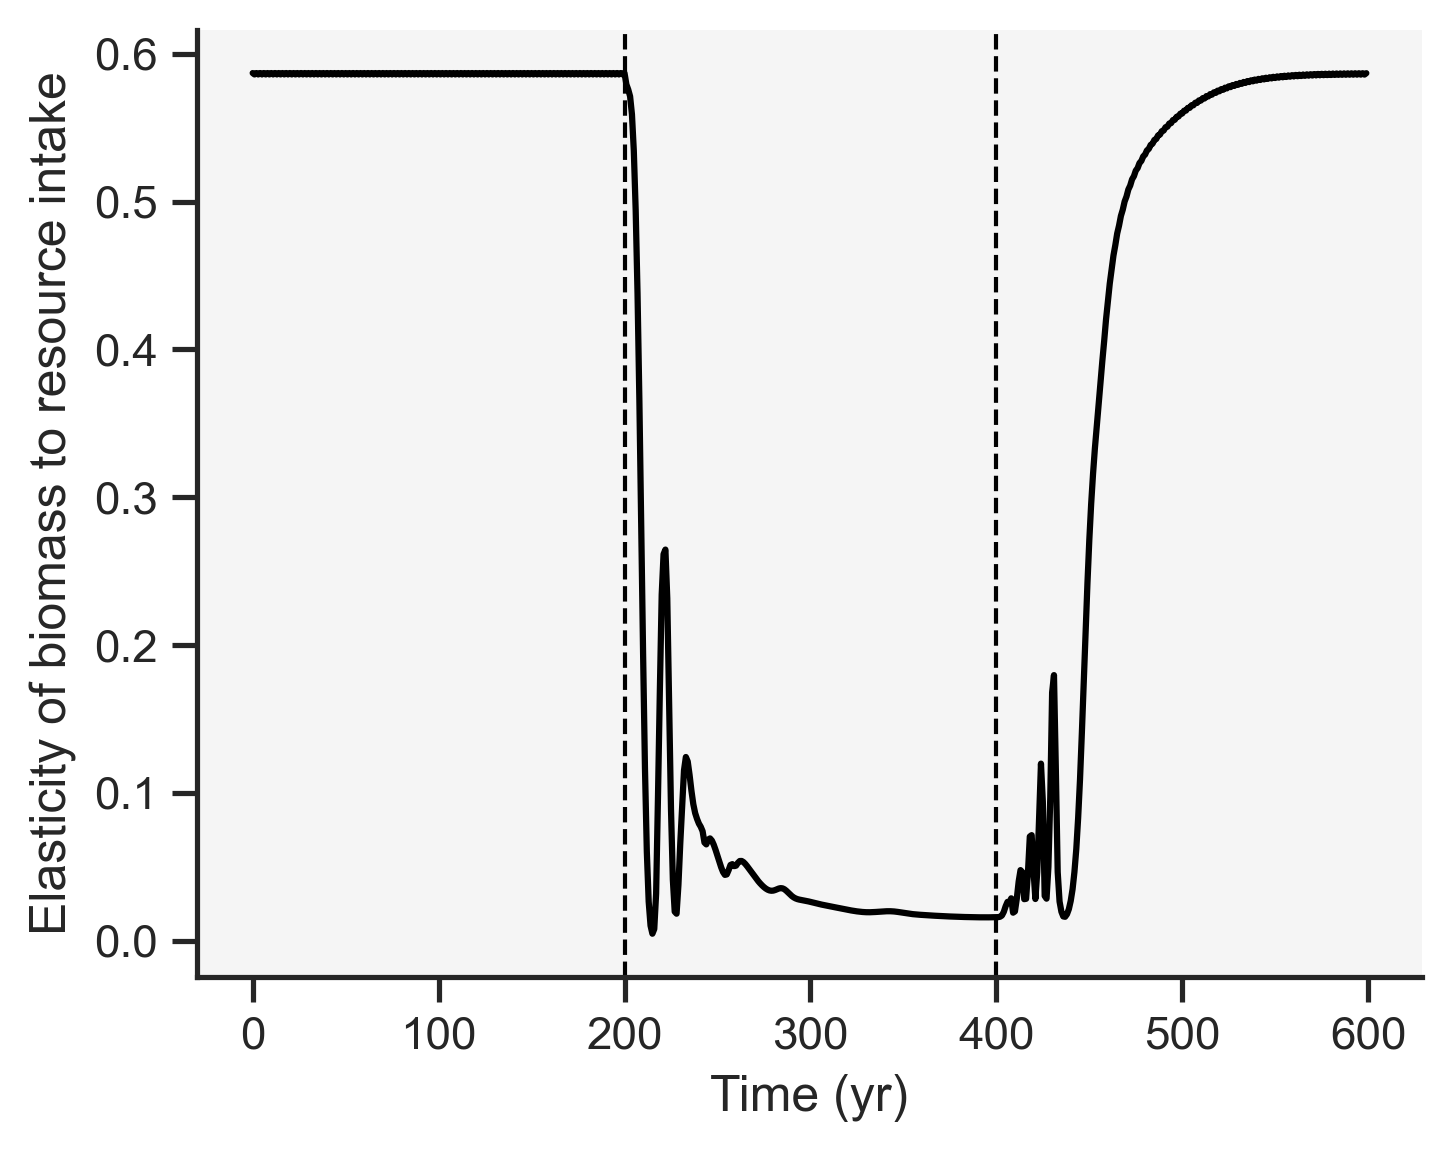

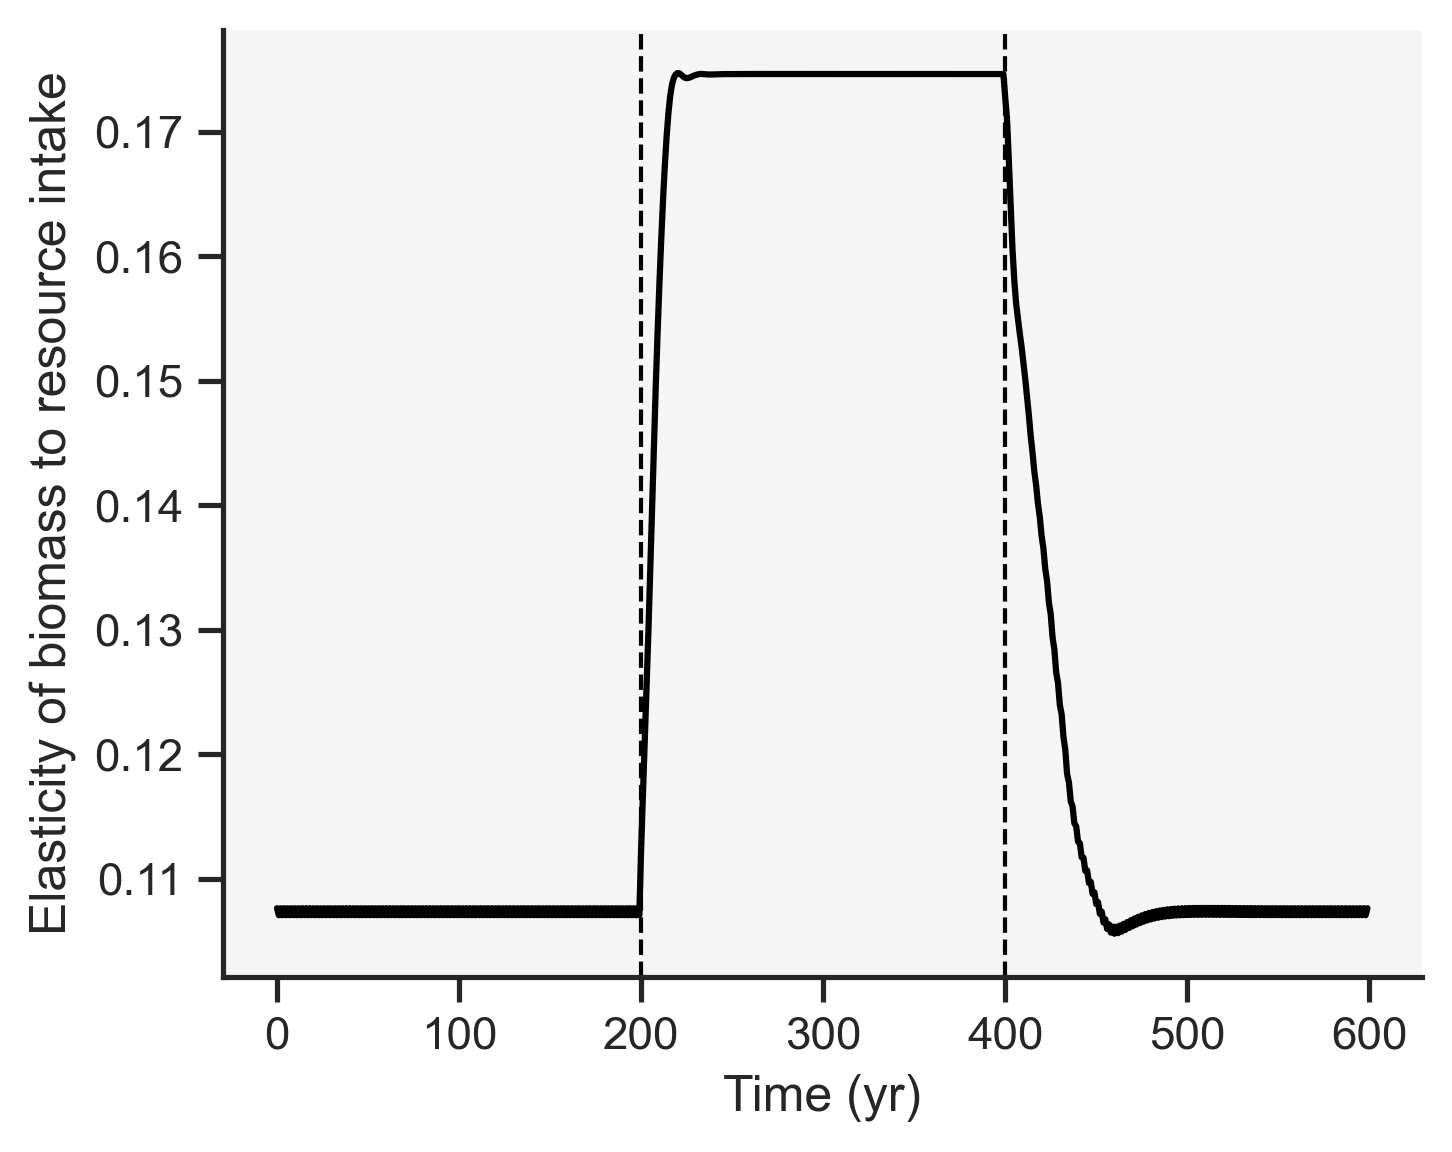

In [6]:
############################
## ASSEMBLE SENSITIVITIES ##
############################

adjoint_sentitivities = torch.cat((adjoint_sensitivity_1, adjoint_sensitivity_2, adjoint_sensitivity_3), dim=0)
adjoint_sentitivities_R = torch.cat((adjoint_sensitivity_1_R, adjoint_sensitivity_2_R, adjoint_sensitivity_3_R), dim=0)
adjoint_sentitivities_G = torch.cat((adjoint_sensitivity_1_G, adjoint_sensitivity_2_G, adjoint_sensitivity_3_G), dim=0)
print(adjoint_sentitivities.shape)

SAVE = SAVEFIGS
FIGSIZE = (5,4)

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(adjoint_sentitivities[:,1], color="black")
# plt.plot(adjoint_sentitivities_R[:,1], color="red")
# plt.plot(adjoint_sentitivities_G[:,1], color="blue")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel("Time (yr)")
plt.ylabel(f"Elasticity of biomass to resource intake")
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-elasticity-aspen.pdf")
plt.show()
plt.rcParams['figure.dpi'] = 100

plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(adjoint_sentitivities[:,2], color="black")
# plt.plot(adjoint_sentitivities_R[:,2], color="red")
# plt.plot(adjoint_sentitivities_G[:,2], color="blue")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel("Time (yr)")
plt.ylabel(f"Elasticity of biomass to resource intake")
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-elasticity-elk.pdf")
plt.show()
plt.rcParams['figure.dpi'] = 100

#
###

In [7]:
##########################
## ASSEMBLE TIME SERIES ##
##########################

TS = torch.cat((predictions_1[6],predictions_2[6],predictions_3[6]), dim=0)

## Compute equilibrium points
eq_1 = torch.mean(TS[190:200],axis=0)
eq_2 = torch.mean(TS[390:400],axis=0)
eq_3 = torch.mean(TS[590:600],axis=0)
print(eq_1)
print(eq_2)
print(eq_3)

#
###

tensor([4.2123e+07, 1.2652e+08, 3.0091e+03, 4.8193e+03, 1.0469e+02, 4.6833e+01],
       dtype=torch.float64)
tensor([1.6348e+07, 3.9859e+06, 9.0809e+03, 3.3323e+03, 0.0000e+00, 0.0000e+00],
       dtype=torch.float64)
tensor([4.2123e+07, 1.2652e+08, 3.0091e+03, 4.8192e+03, 1.0469e+02, 4.6833e+01],
       dtype=torch.float64)


Time to disrupted equilibrium: 69 yr
Time to initial equilibrium: 32 yr


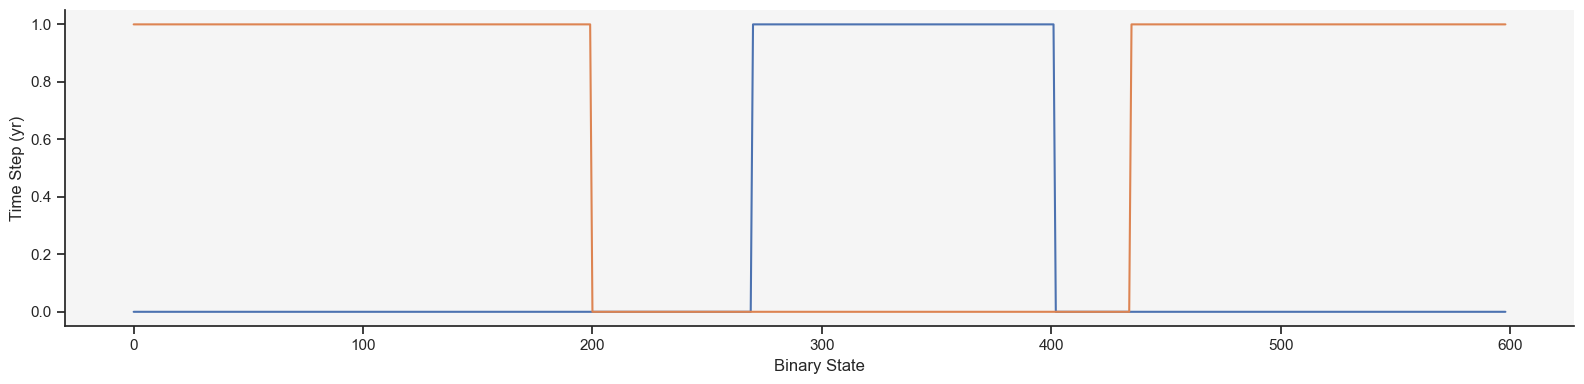

Time to disrupted equilibrium: 126 yr
Time to initial equilibrium: 52 yr


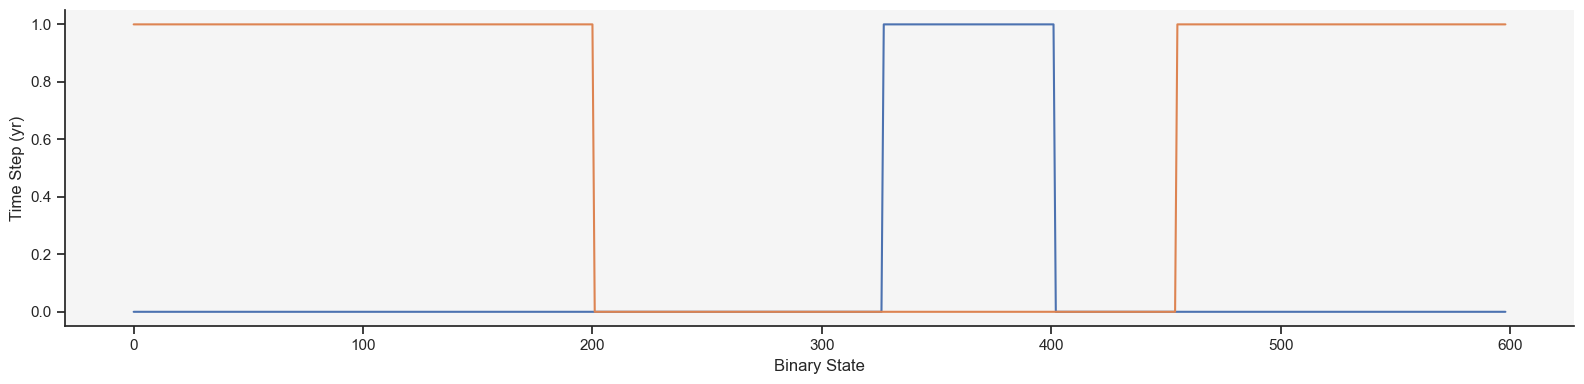

Time to disrupted equilibrium: 23 yr
Time to initial equilibrium: 36 yr


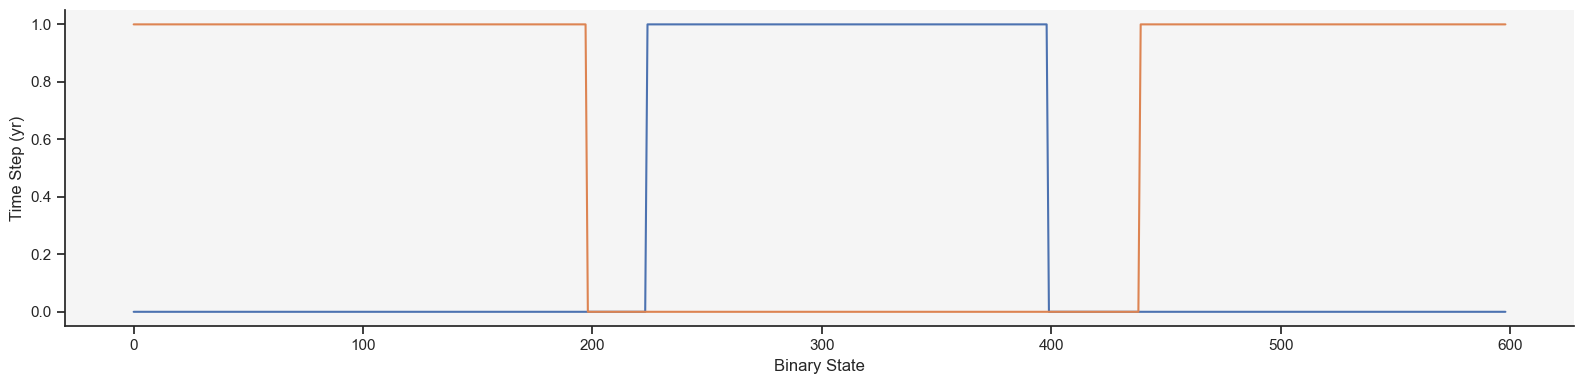

Time to disrupted equilibrium: 23 yr
Time to initial equilibrium: 34 yr


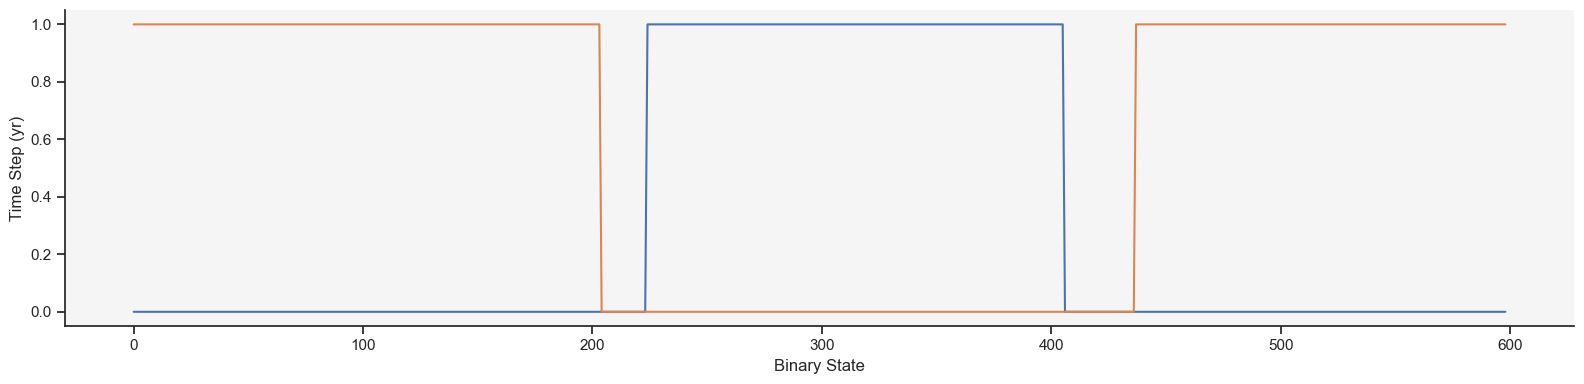

In [9]:
################################
## COMPUTE TIME TO EQUILIBRIA ##
################################

## Trheshold
th = 0.05 # Acceptable difference between recovered and disrupted equilibria in number of individuals
index = 2 # Reference state for determining equilibria

rrecovery_times = []
pperturbation_times = []
for index in [0, 1, 2, 3]:

    ## Perturbation
    perturbation = (torch.abs(TS[:,index] - eq_2[index]) < th * eq_2[index])*1
    perturbation = (((perturbation[1:] + perturbation[0:-1])/2) > 0.5)*1 # Smooth
    perturbation = (((perturbation[1:] + perturbation[0:-1])/2) > 0.5)*1 # Smooth
    perturbation = (((perturbation[1:] + perturbation[0:-1])/2) > 0.5)*1 # Smooth
    perturbation = (((perturbation[1:] + perturbation[0:-1])/2) > 0.5)*1 # Smooth
    if len(np.where(perturbation == 1)[0]) == 0:
        t_perturbation = t_max_2 + t_max_1 + 1
    else:
        t_perturbation = np.where(perturbation == 1)[0][0]
    print(f"Time to disrupted equilibrium: {t_perturbation - (t_max_1 + 1):.0f} yr")
    
    ## Recovery
    recovery = (torch.abs(TS[:,index] - eq_3[index]) < th * eq_3[index])*1
    recovery = (((recovery[1:] + recovery[0:-1])/2) > 0.5)*1 # Smooth
    recovery = (((recovery[1:] + recovery[0:-1])/2) > 0.5)*1 # Smooth
    recovery = (((recovery[1:] + recovery[0:-1])/2) > 0.5)*1 # Smooth
    recovery = (((recovery[1:] + recovery[0:-1])/2) > 0.5)*1 # Smooth
    t_recovery = np.where(recovery == 0)[0][-1]
    print(f"Time to initial equilibrium: {t_recovery - (t_max_1 + t_max_2 + 2):.0f} yr")

    ## Collect
    rrecovery_times += [t_recovery]
    pperturbation_times += [t_perturbation]
    
    ## Visualise
    plt.figure(figsize=(16,4))
    plt.plot(perturbation, label='Perturbation')
    plt.plot(recovery, label='Recovery')
    plt.xlabel('Binary State')
    plt.ylabel('Time Step (yr)')
    plt.tight_layout()
    plt.show()


#
###

In [10]:
print(pperturbation_times)
print(rrecovery_times)

[270, 327, 224, 224]
[434, 454, 438, 436]


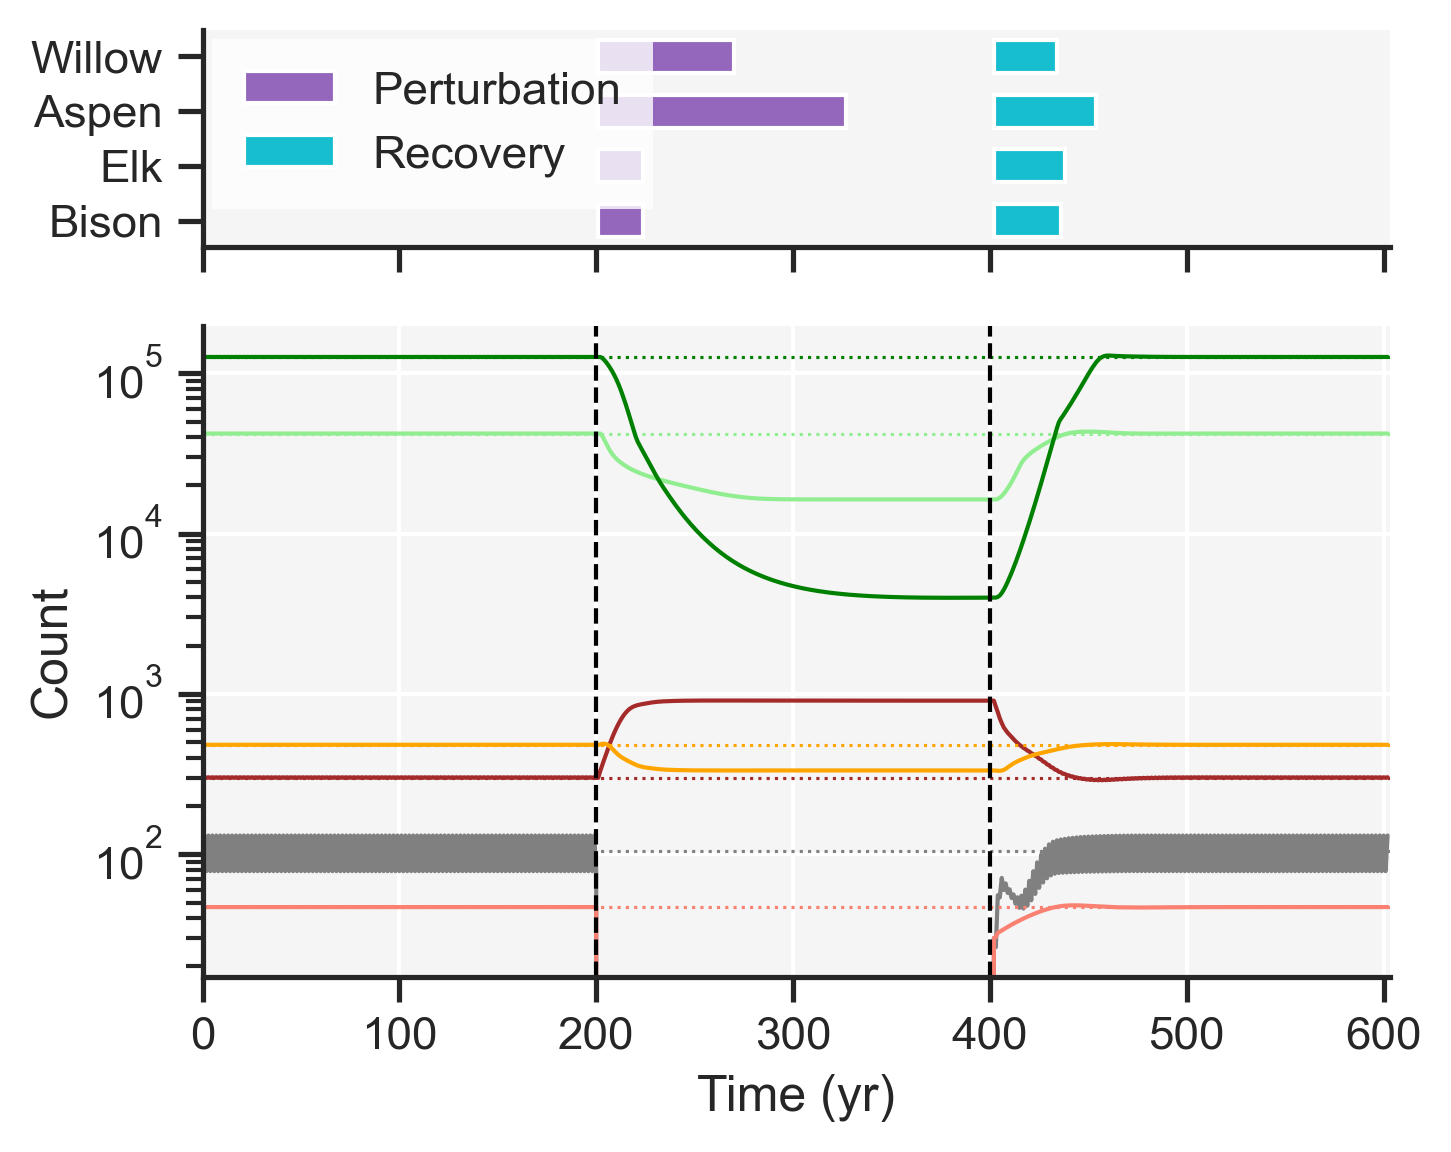

In [11]:
####################
## COMBINED PLOTS ##
####################

## Global variables
FIGRES = 300
FIGSIZE = (5,4)
SAVE = True

##
plt.rcParams['figure.dpi'] = 300

## Create figure
fig, (ax_timeline, ax_ts) = plt.subplots(
    2, 1,
    figsize=FIGSIZE,
    sharex=True,
    gridspec_kw={"height_ratios": [1, 3]}
)


## Top panel
llabels = ['Willow', 'Aspen', 'Elk', 'Bison', 'Wolves', 'Cougars']
starts = {"Perturbation": 201, "Recovery": 402}
ends = {"Perturbation": pperturbation_times, "Recovery": rrecovery_times}
colors = {"Perturbation": "tab:purple", "Recovery": "tab:cyan"}
#
for i in range(len(pperturbation_times)):
    for phase in starts:
        ax_timeline.barh(
            i,
            ends[phase][i] - starts[phase],
            left=starts[phase],
            height=0.6,
            color=colors[phase],
            label=phase if i == 0 else ""
        )
#
ax_timeline.set(
    yticks=range(len(pperturbation_times)),
    yticklabels=[f"{llabels[i]}" for i in range(len(pperturbation_times))],
    # title="Perturbation and Recovery Periods"
)
#
# ax_timeline.set_title('a.', loc='right', fontweight='bold')
ax_timeline.invert_yaxis()
ax_timeline.grid(False)
# ax_timeline.legend(loc="upper left", frameon=False)
leg = ax_timeline.legend(loc='upper left', ncol=1, fontsize=11)
frame = leg.get_frame()
frame.set_boxstyle('square')
frame.set_facecolor('white')
frame.set_edgecolor('none')

## Bottom panel
ttimes = np.arange(len(TS))
llabels = ['Willow', 'Aspen', 'Elk', 'Bison', 'Wolves', 'Cougars']
ccolors = ['lightgreen', 'green', 'Brown', 'Orange', 'Grey', 'Salmon']
sscales = [0.001, 0.001, 0.1, 0.1, 1.0, 1.0]
#
for i in range(TS.shape[1]):
    ax_ts.plot(
        ttimes,
        TS[:, i] * sscales[i],
        label=f"{llabels[i]} ($\\times$ {np.round(1/sscales[i]):.0f})",
        lw=1.0,
        color=ccolors[i]
    )

    x = [0, len(ttimes)]
    y = torch.mean(TS[0:100, i]) * sscales[i]
    ax_ts.plot(x, [y, y], linestyle="dotted", lw=0.75, color=ccolors[i])
#
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
#
ax_ts.set(
    xlabel='Time (yr)',
    ylabel='Count'
)
ax_ts.set_yscale('log')
#
# ax_ts.set_title('b.', loc='right', fontweight='bold')
"""
leg = ax_ts.legend(loc='upper left', ncol=1)
frame = leg.get_frame()
frame.set_boxstyle('square')
frame.set_edgecolor('none')
frame.set_facecolor('white')
"""
#
ax_ts.grid(color='white')

## Final layout
ax_ts.set_xlim(0, 603)
plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-extirpation-short-summary.pdf")
plt.show()

plt.rcParams['figure.dpi'] = 100

#
###

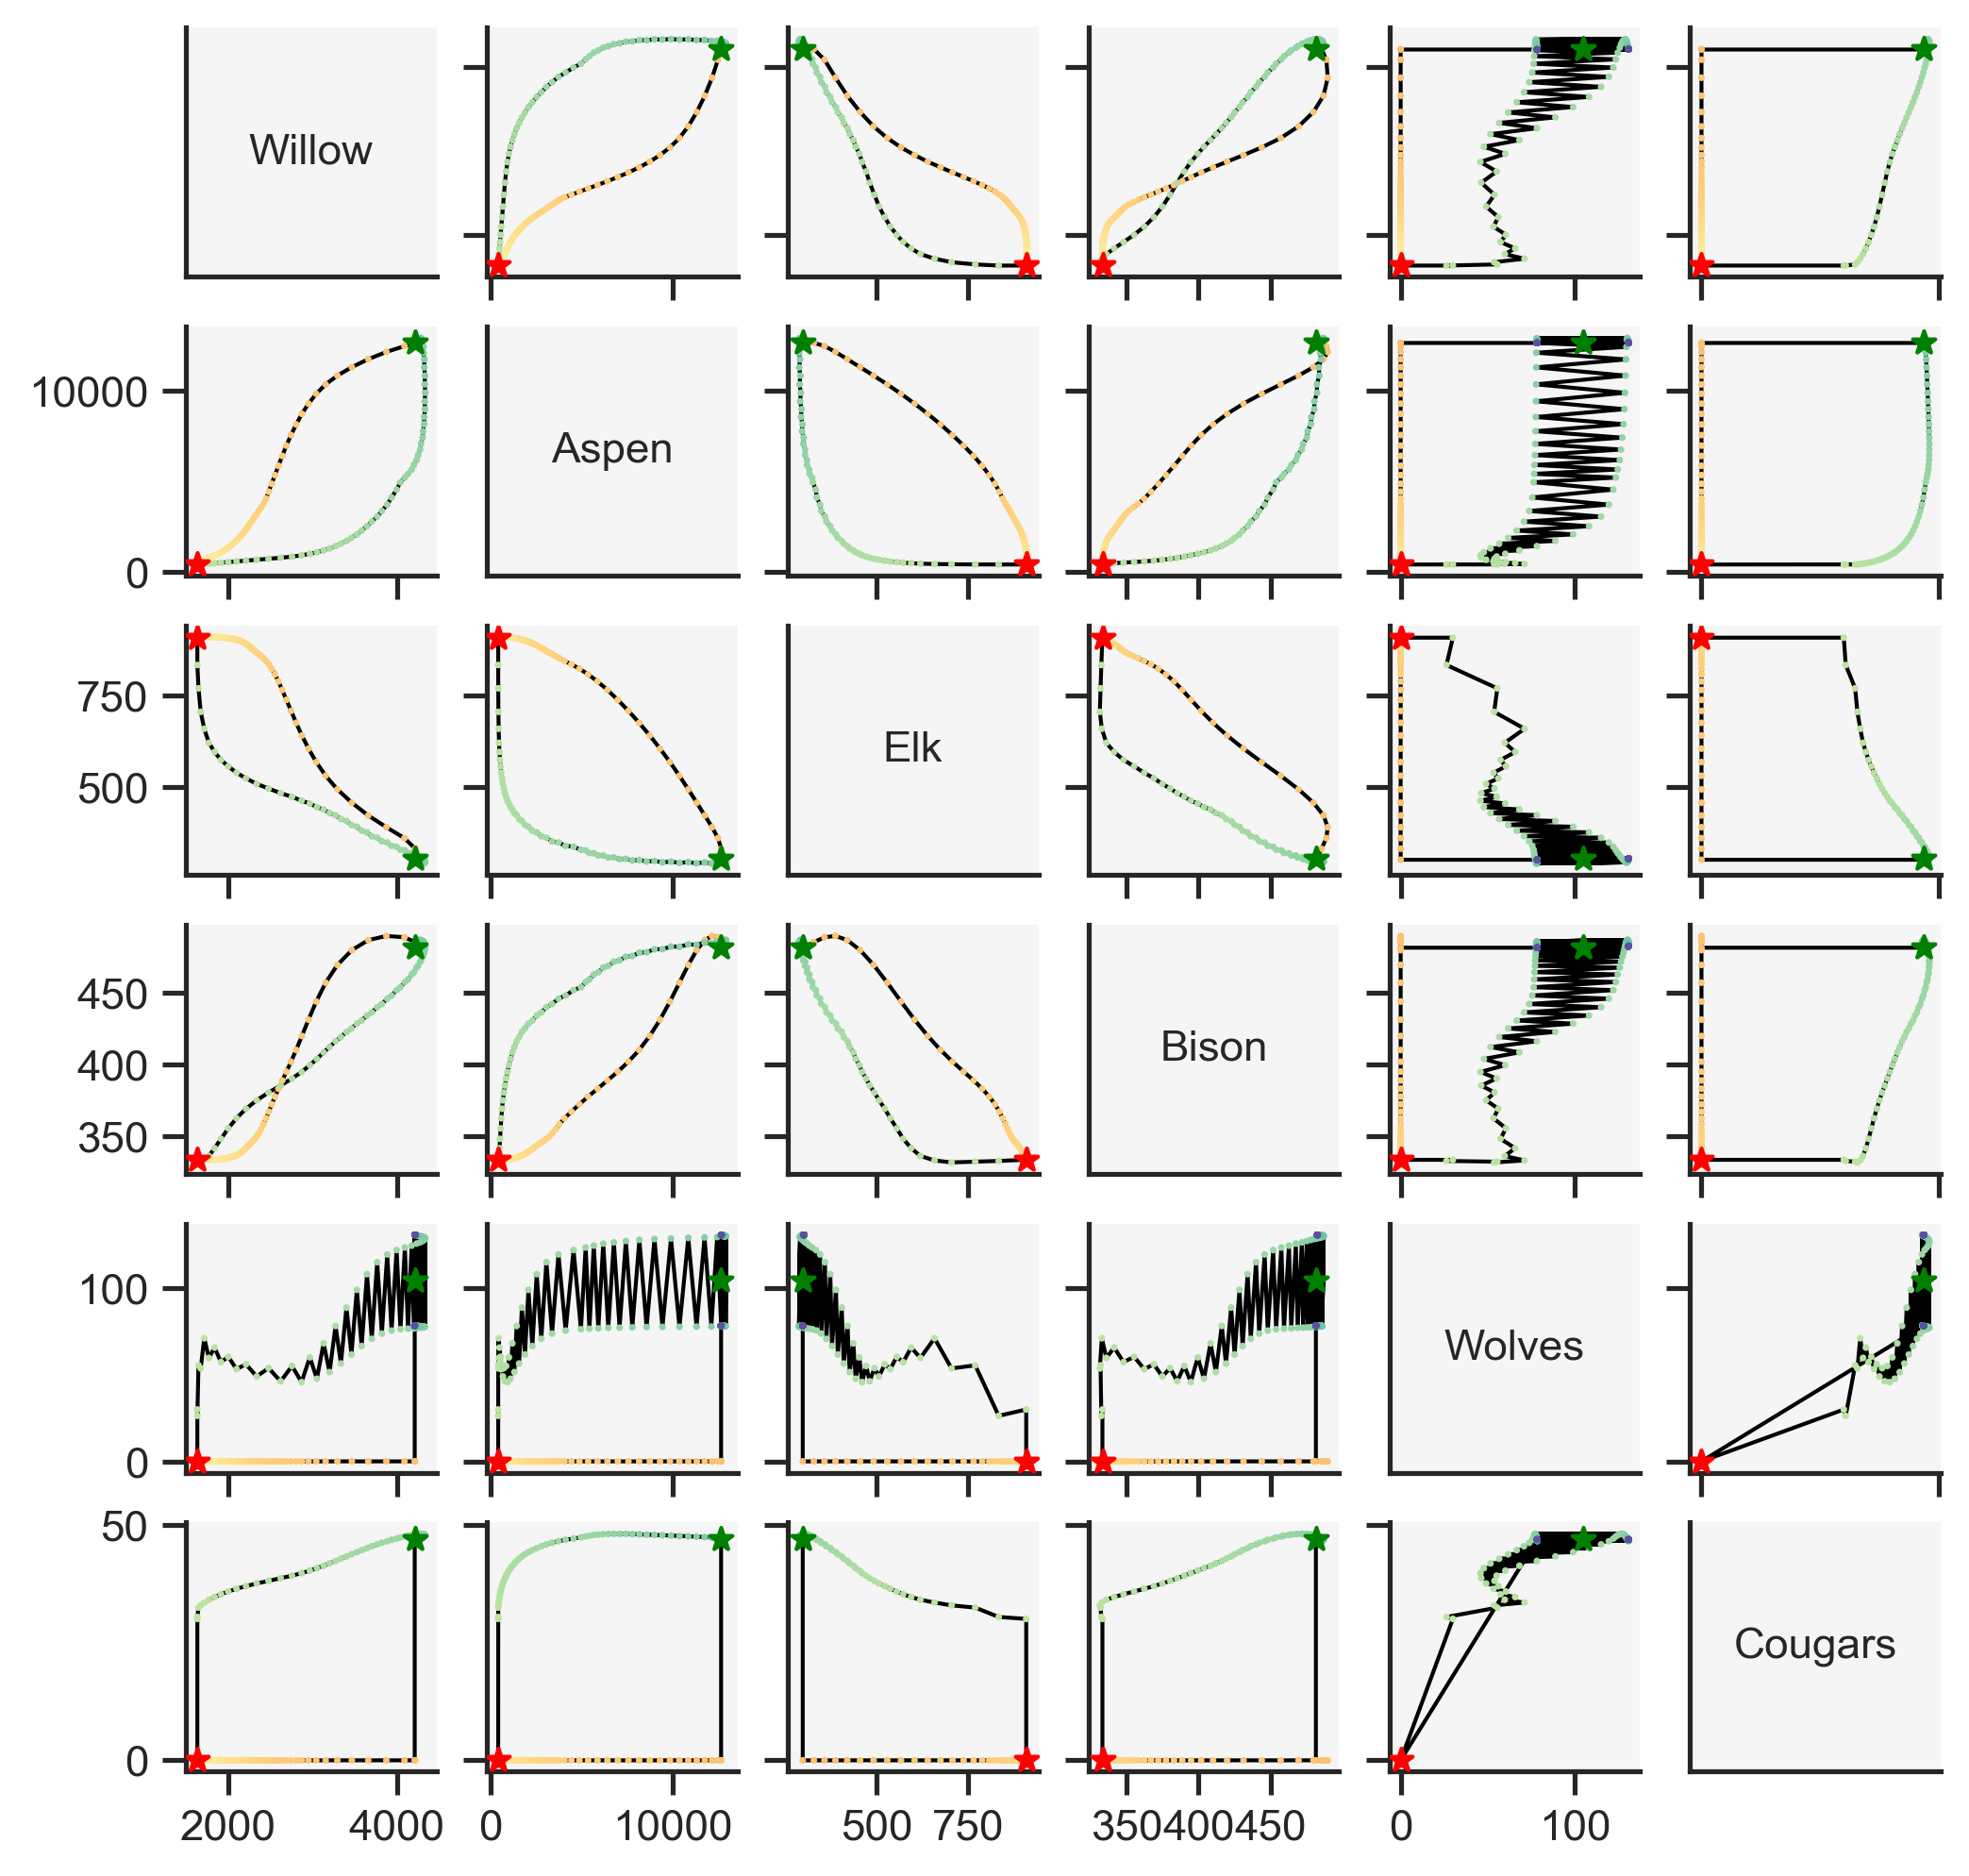

In [12]:
###################
## VISUALISATION ##
###################

## Global variables
FIGRES = 300
FIGSIZE = (8,8)
SAVE = SAVEFIGS

##
plt.rcParams['figure.dpi'] = 300

ttimes = np.arange(len(TS))
llabels = ['Willow', 'Aspen', 'Elk', 'Bison', 'Wolves', 'Cougars']
ccolors = ['Red', 'Blue', 'Brown', 'Orange', 'Grey', 'Salmon']
sscales = [0.0001, 0.0001, 0.1, 0.1, 1.0, 1.0]
ccolors = np.linspace(0, 1, TS.shape[0])
#
n = TS.shape[1]
fig, axes = plt.subplots(n, n, figsize=FIGSIZE, dpi=300)

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        
        if i != j:
            ax.plot(TS[:, j] * sscales[j], TS[:, i] * sscales[i],
                    lw=1.0, color='black')
            ax.scatter(TS[:, j] * sscales[j], TS[:, i] * sscales[i],
                       c=ccolors, cmap='Spectral', s=0.5, zorder=2)
            ax.scatter(eq_1[j] * sscales[j], eq_1[i] * sscales[i],
                       color='green', zorder=3, marker='*')
            ax.scatter(eq_2[j] * sscales[j], eq_2[i] * sscales[i],
                       color='red', zorder=3, marker='*')
        else:
            if i == j:
                # Remove only the ticks, keep the box (spines)
                ax.set_xticks([])
                ax.set_yticks([])
                # Optional: add label text in the middle
                ax.text(0.5, 0.5, llabels[i], fontsize=11, ha='center', va='center', transform=ax.transAxes)
            # else:
            #     ax.text(0.5, 0.5, llabels[i], fontsize=11, ha='center', va='center', color='white')
            #     ax.axis('off')
        
        # Hide inner tick labels (keep ranges consistent)
        if i < n - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])
        
        # Optionally add small tick marks even if labels are hidden
        ax.tick_params(axis='x', which='both', bottom=True, top=False)
        ax.tick_params(axis='y', which='both', left=True, right=False)

# Adjust spacing for visibility
# plt.tight_layout()
if SAVE:
    plt.savefig(f"figures/{NBCODE}-extirpation-short-trajectories.pdf")
plt.show()

##
plt.rcParams['figure.dpi'] = 100

#
###

In [13]:
###################
## FORMAT OUTPUT ##
###################

## Format output
zzz, tt_1, DDt_1, BBt_1, PPt_1, GGt_1, NNNt_1, NNNNzt_1, ttotal_biomass_1 = predictions_1
zzz, tt_2, DDt_2, BBt_2, PPt_2, GGt_2, NNNt_2, NNNNzt_2, ttotal_biomass_2 = predictions_2
zzz, tt_3, DDt_3, BBt_3, PPt_3, GGt_3, NNNt_3, NNNNzt_3, ttotal_biomass_3 = predictions_3
DDt = torch.concatenate((DDt_1, DDt_2, DDt_3), dim=0)
BBt = torch.concatenate((BBt_1, BBt_2, BBt_3), dim=0)
PPt = torch.concatenate((PPt_1, PPt_2, PPt_3), dim=0)
GGt = torch.concatenate((GGt_1, GGt_2, GGt_3), dim=0)
NNNt = torch.concatenate((NNNt_1, NNNt_2, NNNt_3), dim=0)
NNNNzt = torch.concatenate((NNNNzt_1, NNNNzt_2, NNNNzt_3), dim=0)
ttotal_biomass = torch.concatenate((ttotal_biomass_1, ttotal_biomass_2, ttotal_biomass_3), dim=0)
tt = torch.linspace(0, 600, DDt.shape[0]).detach().cpu().numpy()

##
NNNNzt_new = [] # (time, species, phenotype) --> (species, time, phenotype)
for i in range(6):
    NNNzt_new = []
    for NNNzt in NNNNzt:
        NNNzt_new += [NNNzt[i].clone()]
    NNNNzt_new += [torch.stack(NNNzt_new)]
NNNNzt = torch.stack(NNNNzt_new)

##
FIGSIZE = (16//4, 12//6)

print(zzz[:,None,:].shape)
print(NNNNzt.shape)
print((zzz[:,None,:] * NNNNzt).sum(2).shape)

#
###

torch.Size([6, 1, 500])
torch.Size([6, 603, 500])
torch.Size([6, 603])


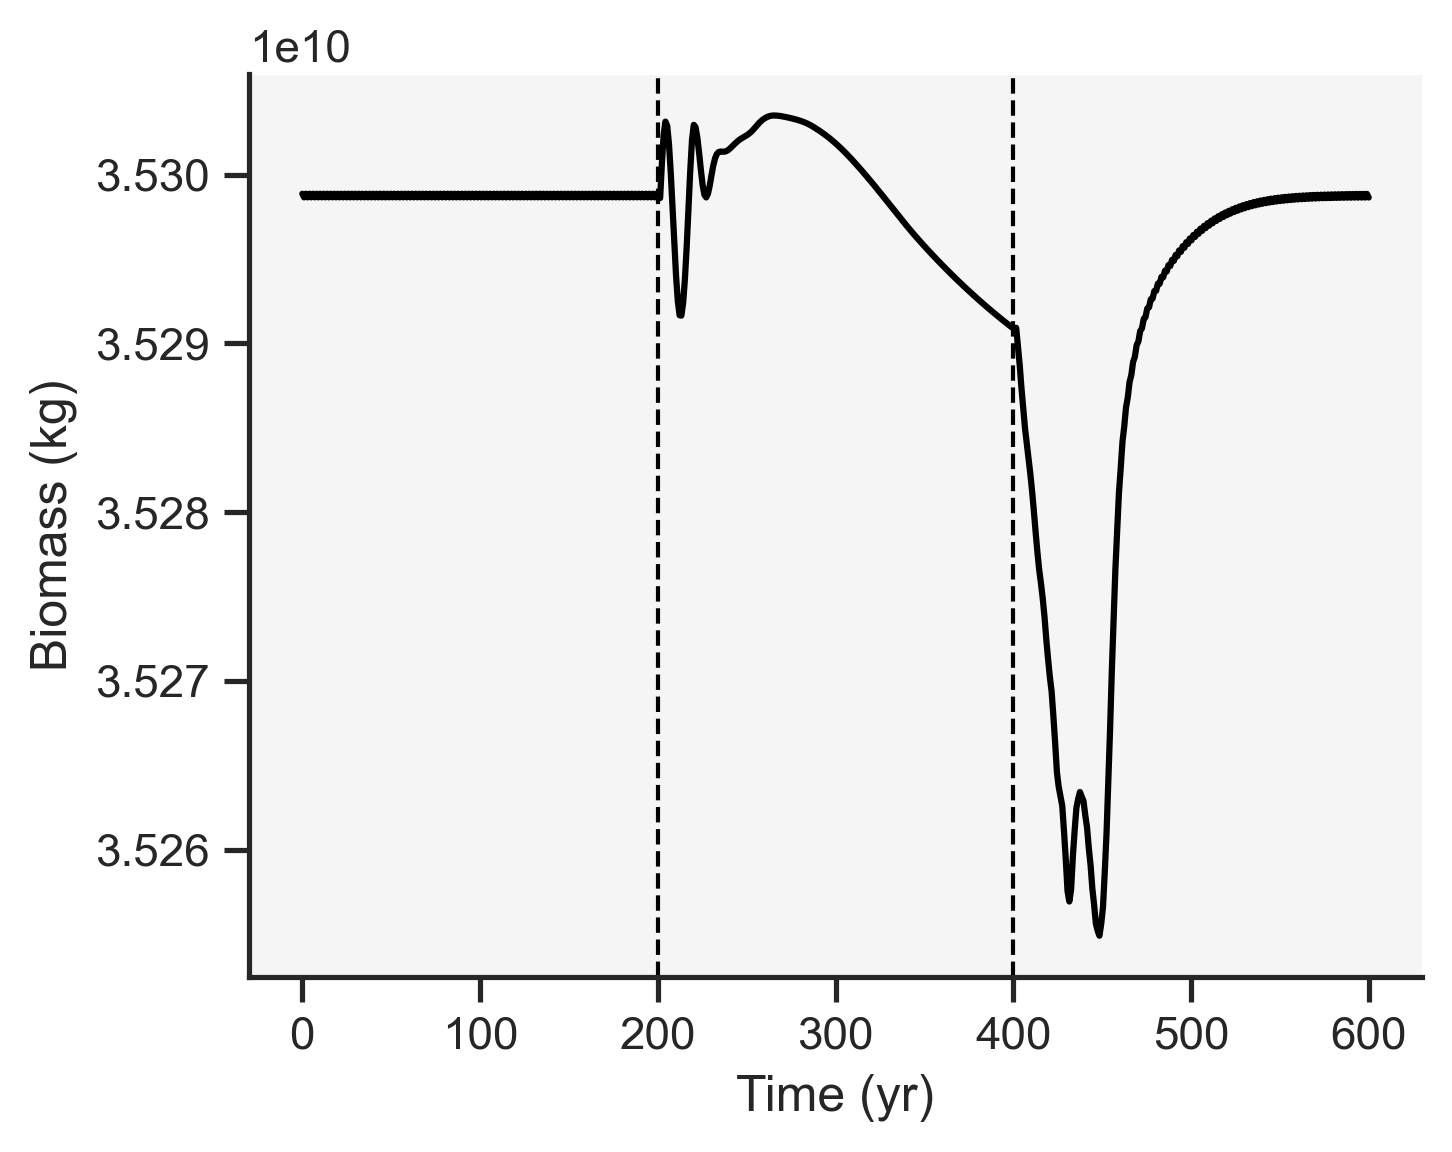

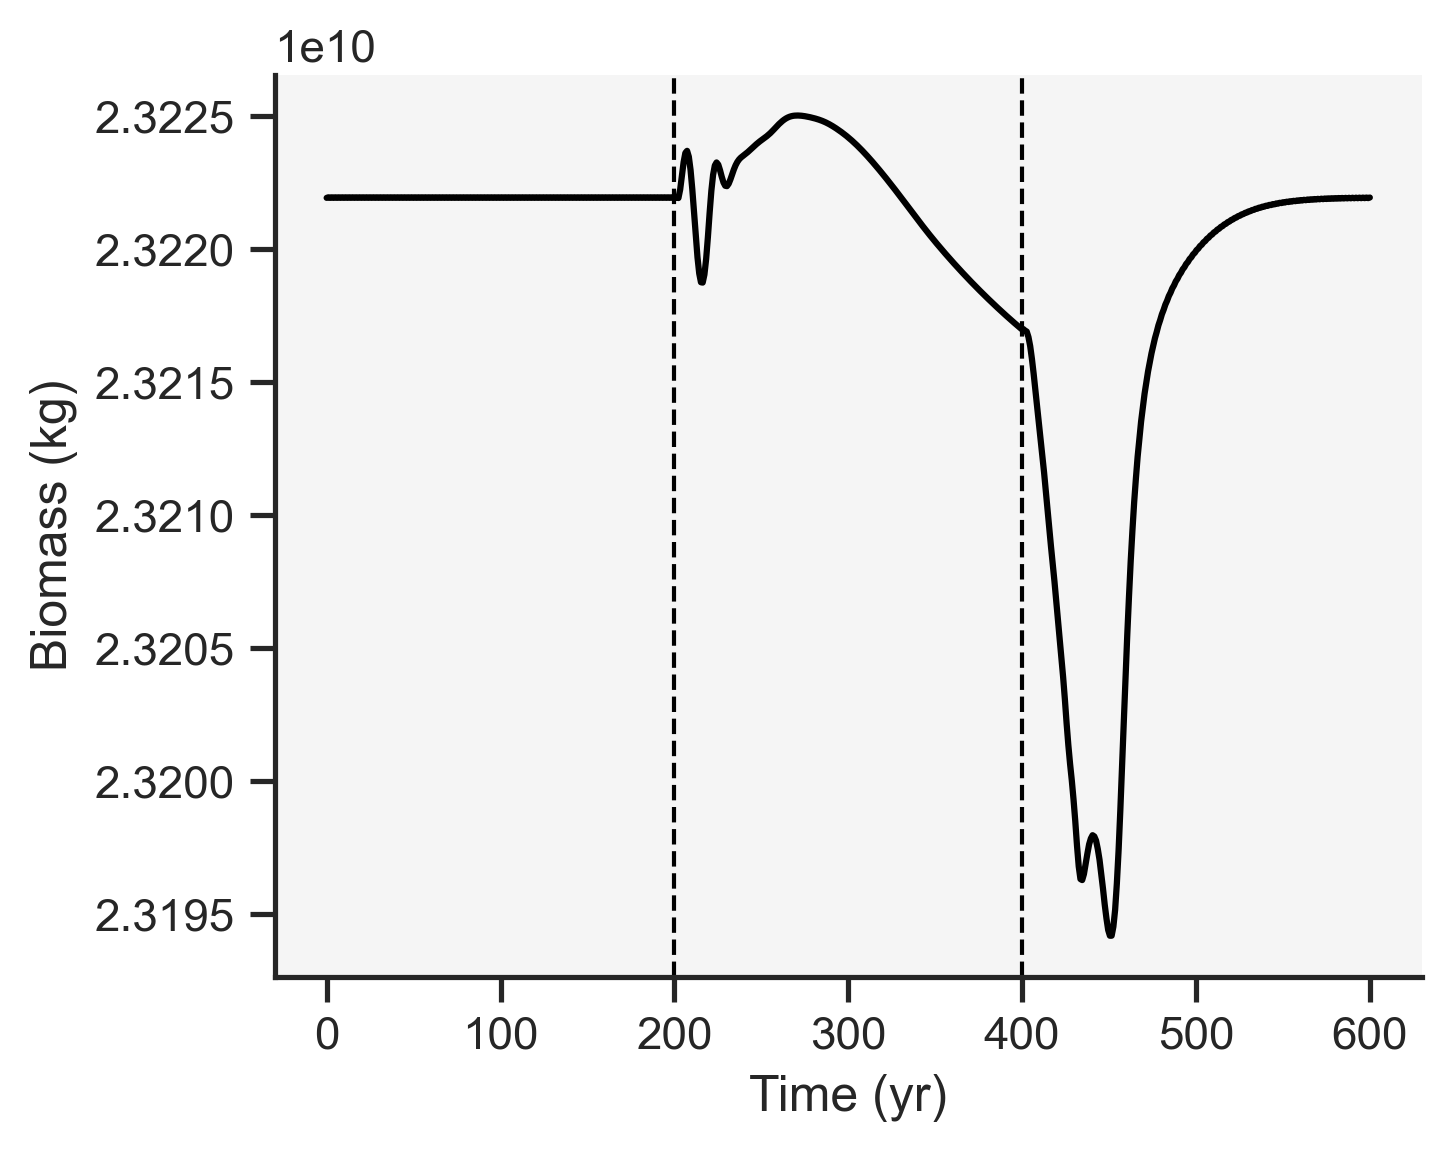

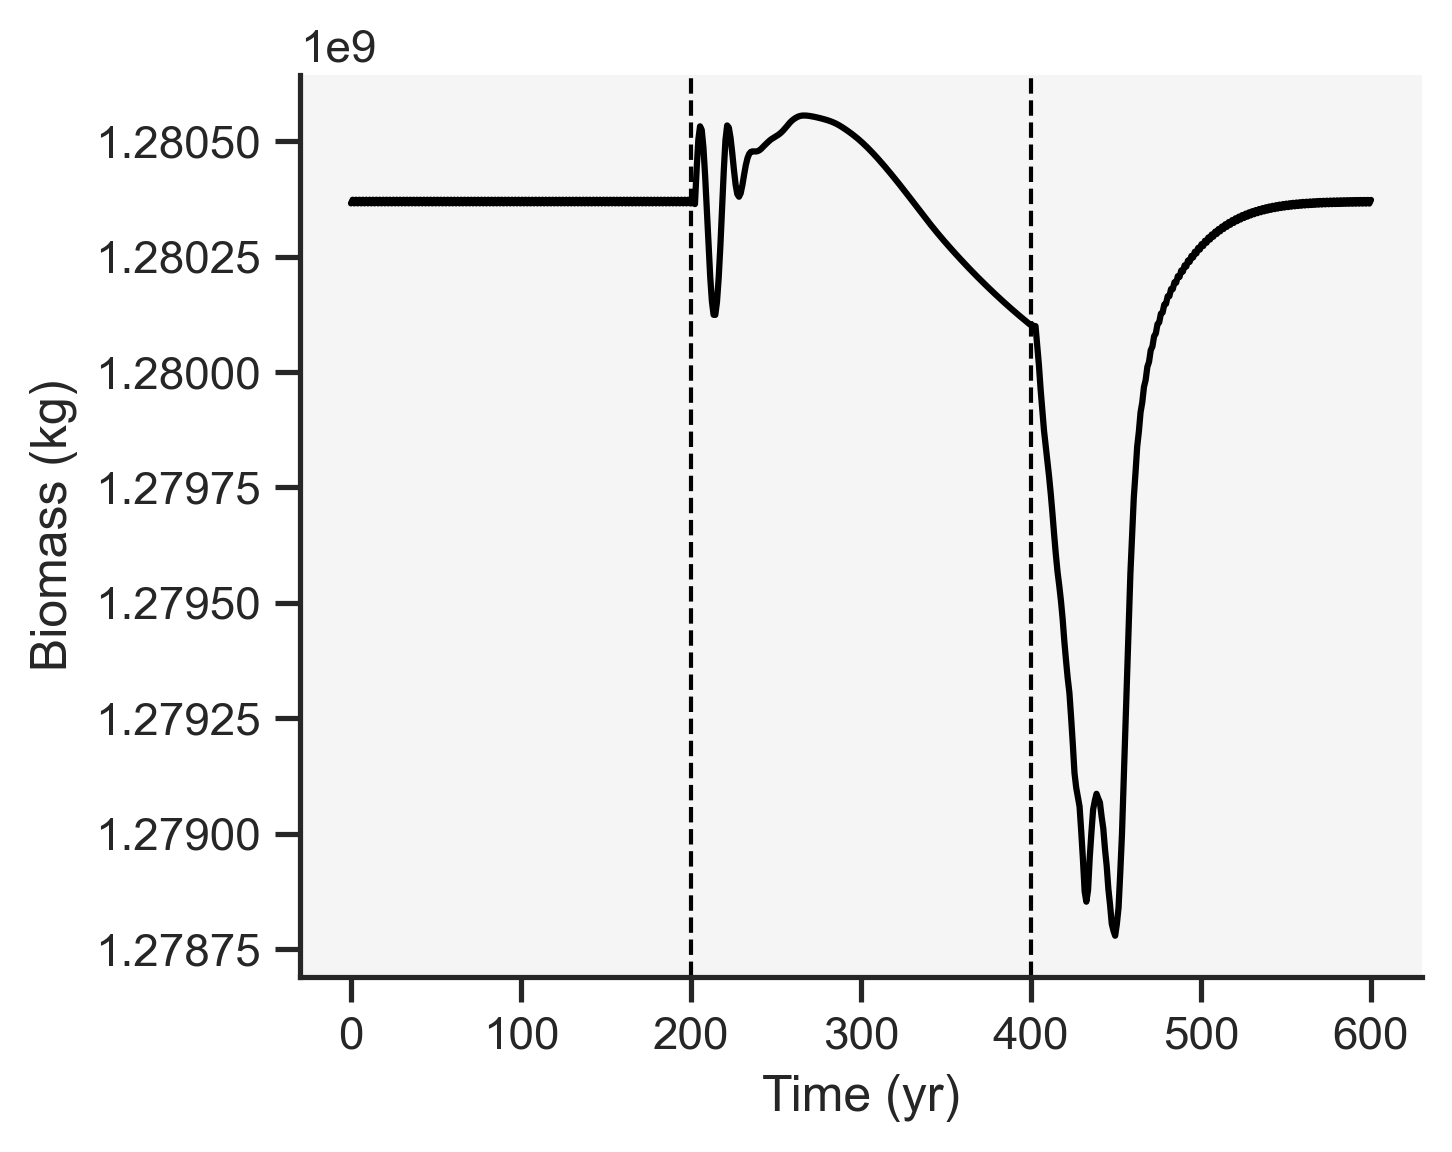

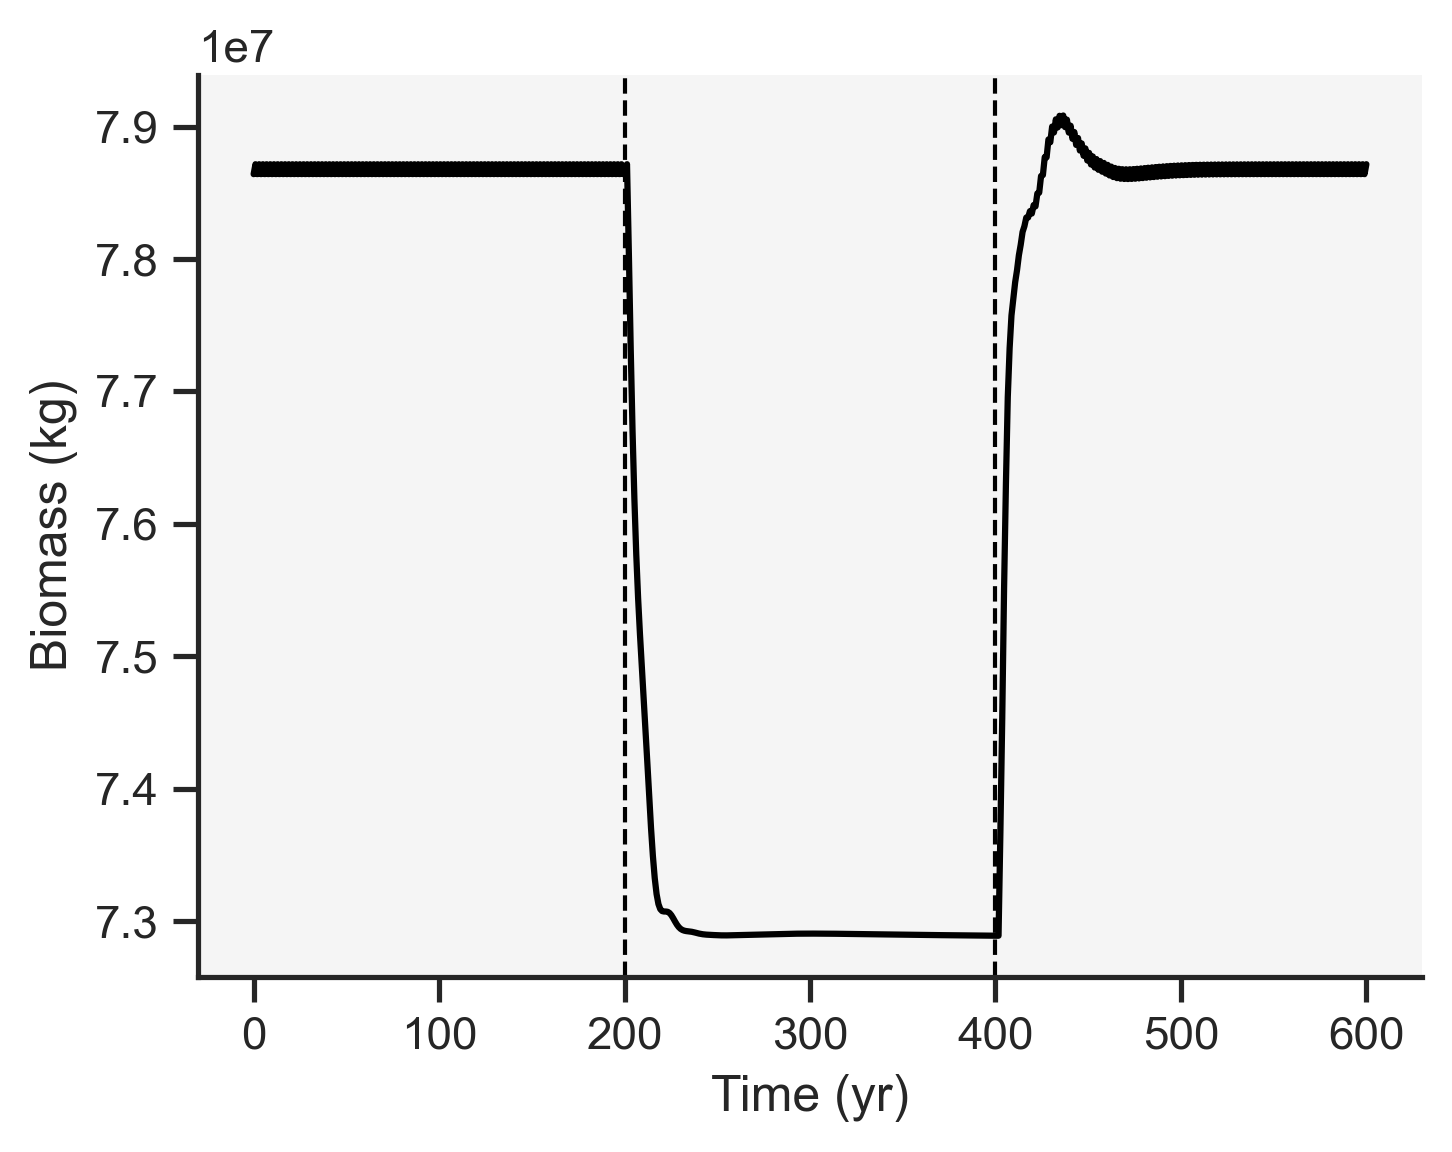

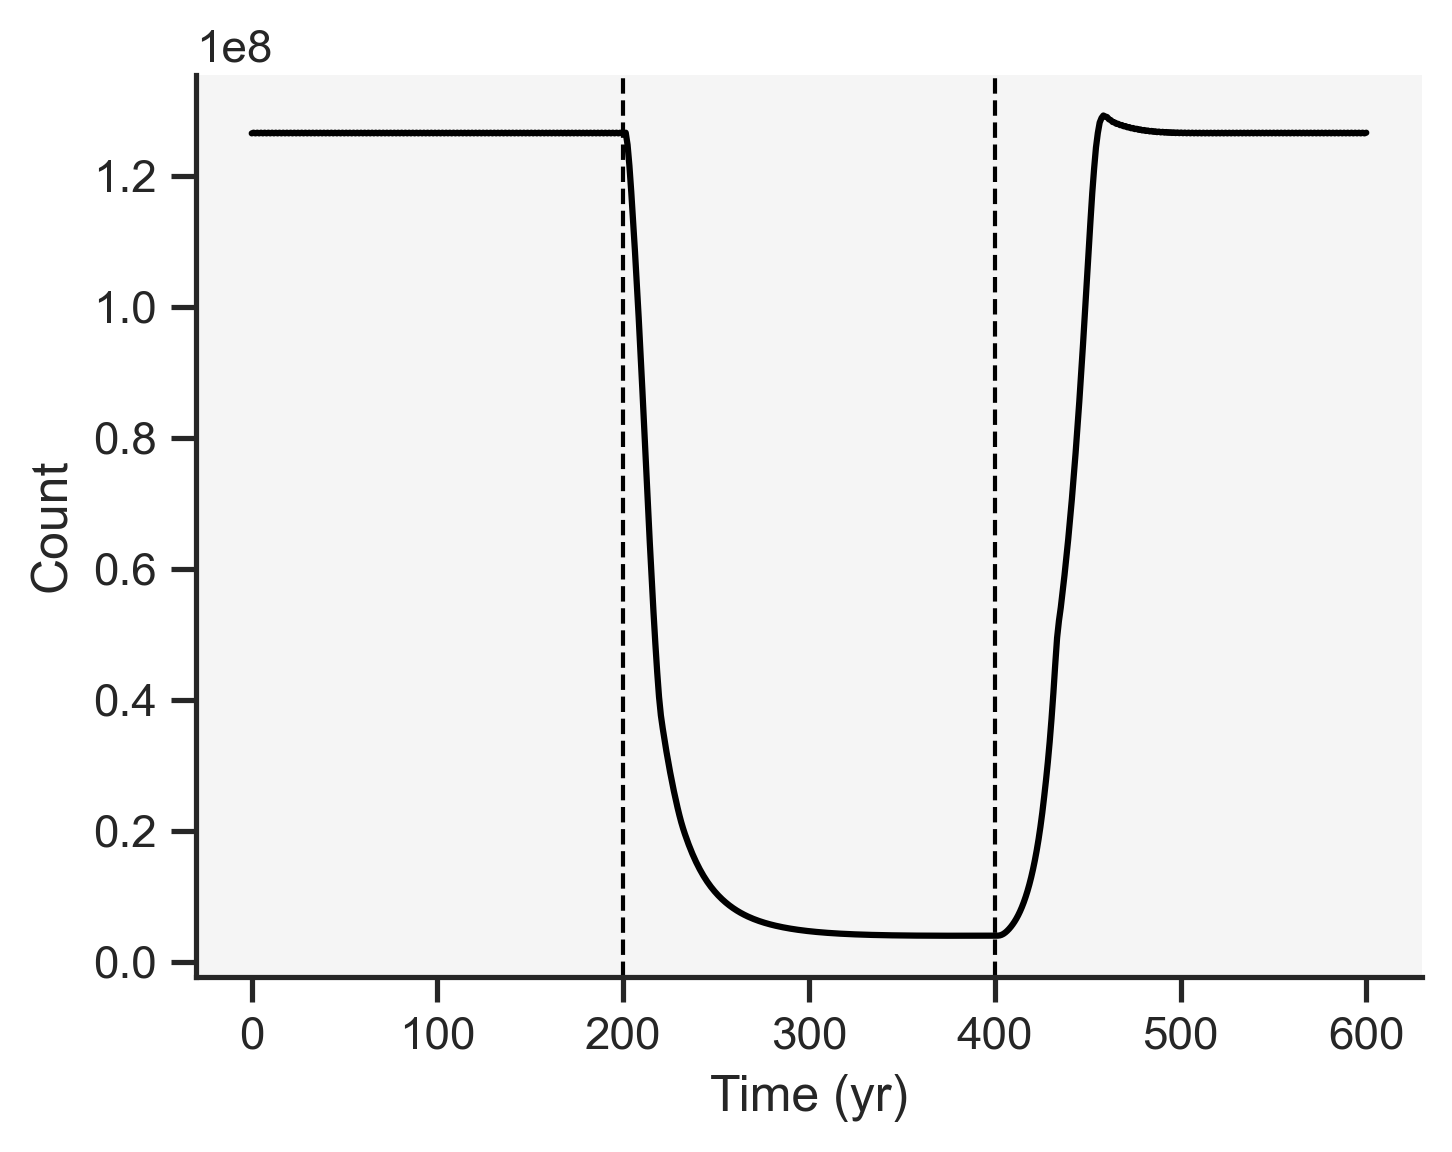

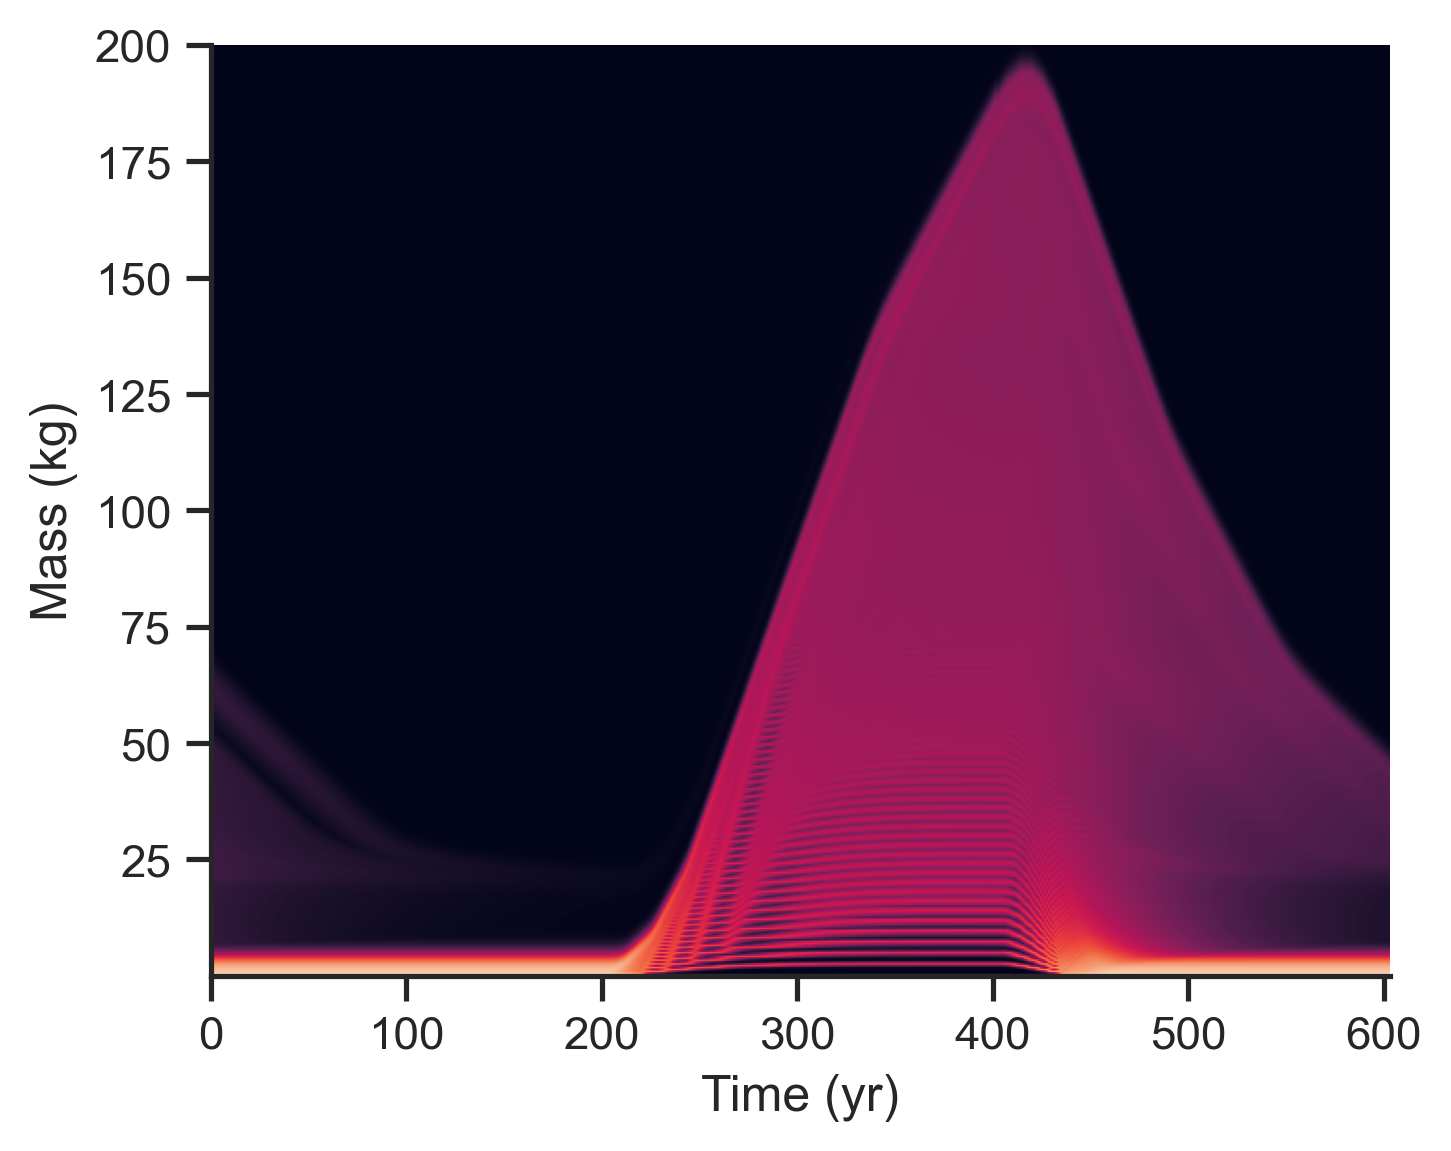

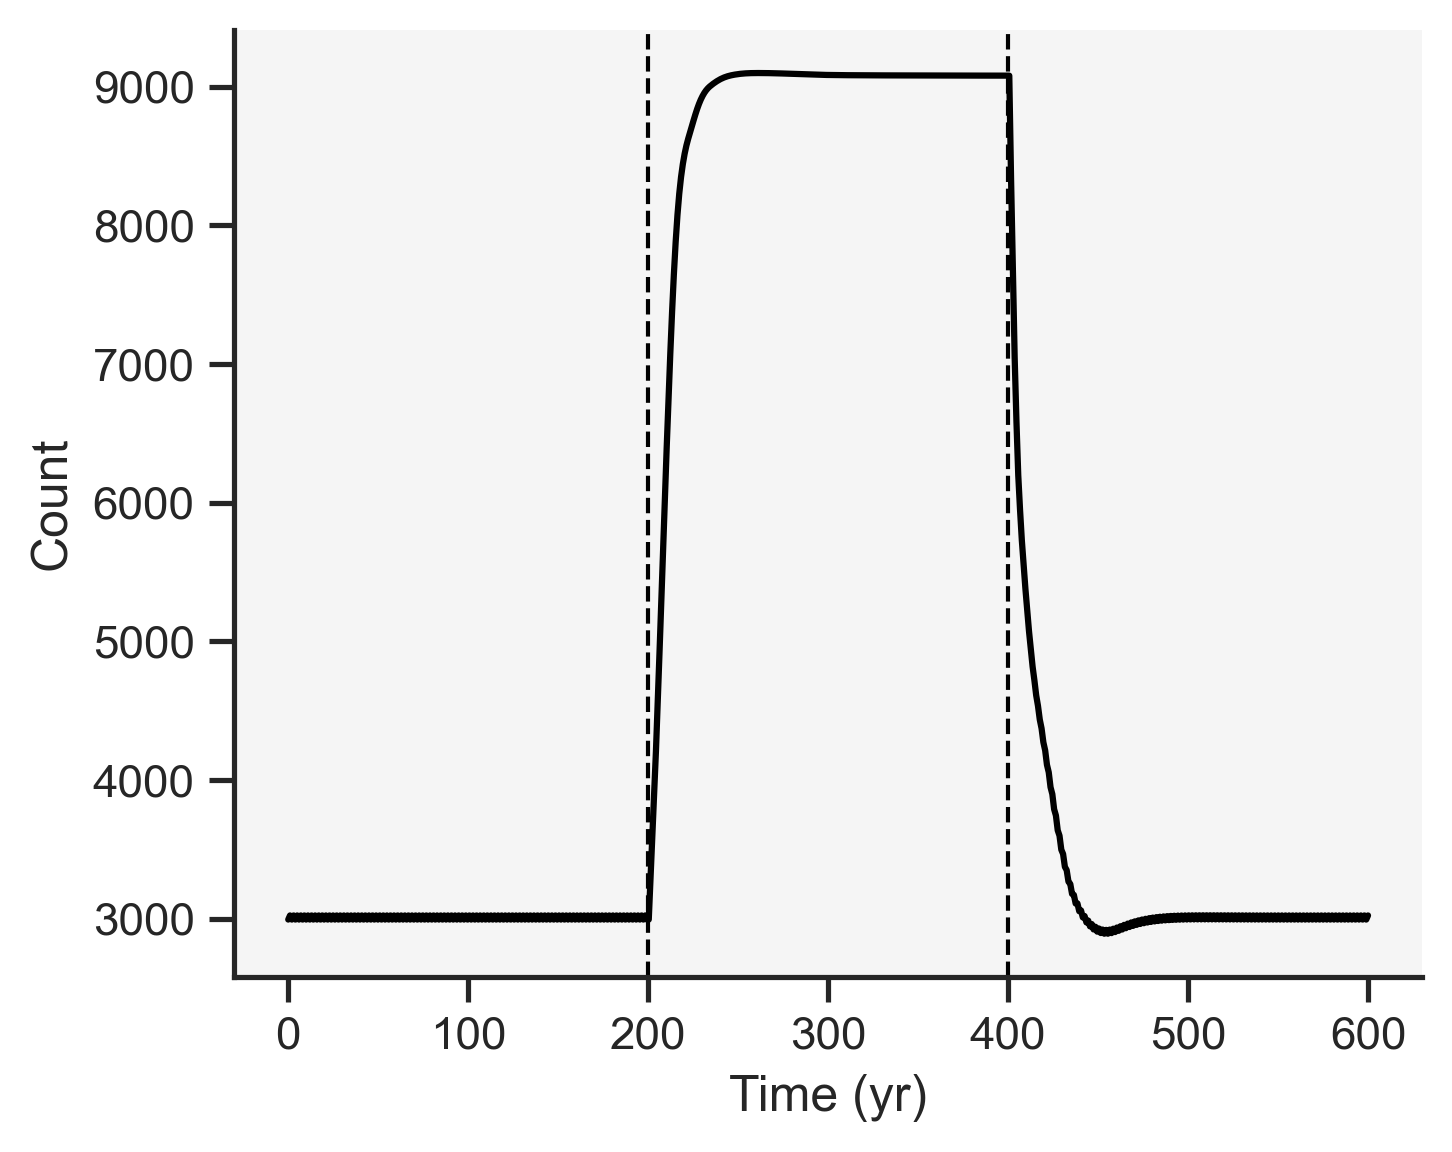

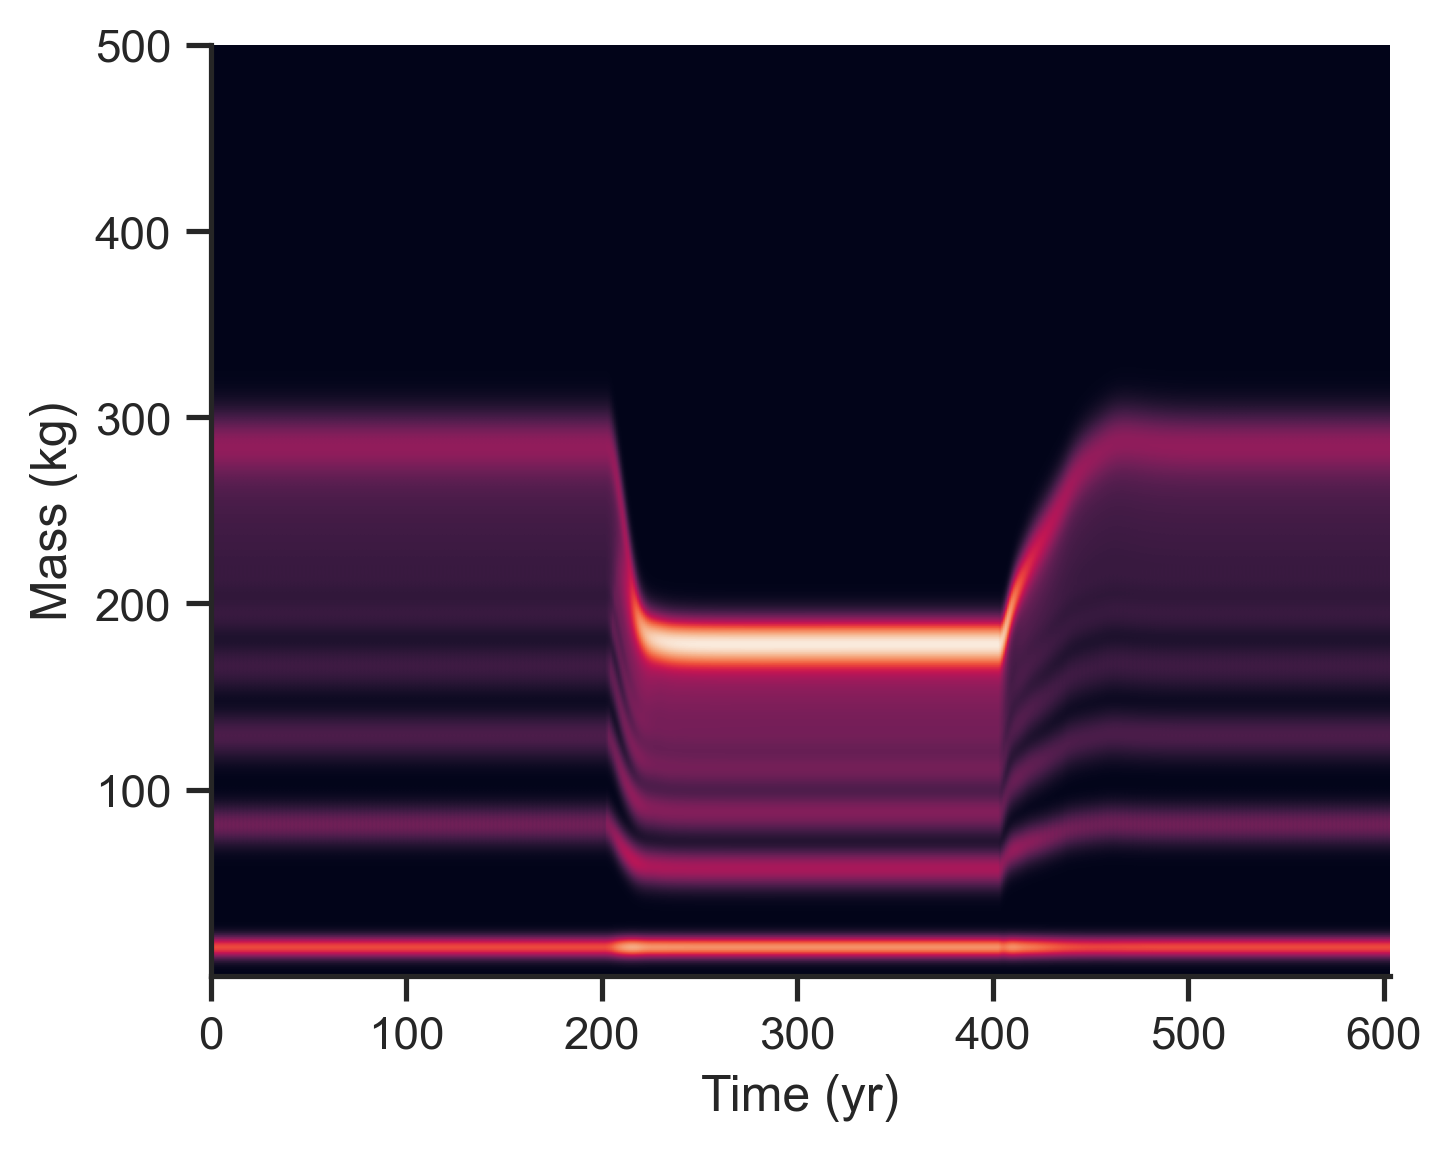

In [14]:
###################
## FIGURE PANELS ##
###################

## Global parameters
SAVE = SAVEFIGS
FIGSIZE = (5,4)

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, DDt, color="black")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel('Time (yr)')
plt.ylabel('Biomass (kg)')
plt.tight_layout()
plt.show()
plt.rcParams['figure.dpi'] = 100

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, BBt, color="black")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel('Time (yr)')
plt.ylabel('Biomass (kg)')
plt.tight_layout()
plt.show()
plt.rcParams['figure.dpi'] = 100

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, PPt, color="black")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel('Time (yr)')
plt.ylabel('Biomass (kg)')
plt.tight_layout()
plt.show()
plt.rcParams['figure.dpi'] = 100

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, GGt, color="black")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel('Time (yr)')
plt.ylabel('Biomass (kg)')
plt.tight_layout()
plt.show()
plt.rcParams['figure.dpi'] = 100

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, NNNt[:,1], color="black")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel('Time (yr)')
plt.ylabel('Count')
plt.tight_layout()
if SAVE: plt.savefig(f"figures/{NBCODE}-extirpation-short-aspen-count.pdf")
plt.show()
plt.rcParams['figure.dpi'] = 100

##
"""
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, (zzz[:,None,:] * NNNNzt).sum(2)[1], color="black")
plt.xlabel('Time (yr)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()
plt.rcParams['figure.dpi'] = 100
"""

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
exponents = [.25, 0.1, .5, .25, .25, .25]
ttitles = ['d.', 'e.', 'f.', 'g.', 'h.', 'i.']
i = 1
k = 0
zz = zzz[i]
plt.imshow(NNNNzt[i].T**exponents[i], origin='lower', aspect='auto', extent=[0, NNNNzt[i].shape[0], zzz[i].min(), zzz[i].max()])    
plt.xlabel('Time (yr)')
plt.ylabel('Mass (kg)')
# plt.title(ttitles[k], loc='right', fontweight='bold')
plt.tight_layout()
if SAVE: plt.savefig(f"figures/{NBCODE}-extirpation-short-aspen-biomass.pdf")
plt.show()
plt.rcParams['figure.dpi'] = 100

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
plt.plot(tt, NNNt[:,2], color="black")
plt.axvline(200, linestyle="dashed", color="black", lw=1.0)
plt.axvline(400, linestyle="dashed", color="black", lw=1.0)
plt.xlabel('Time (yr)')
plt.ylabel('Count')
plt.tight_layout()
if SAVE: plt.savefig(f"figures/{NBCODE}-extirpation-short-elk-count.pdf")
plt.show()
plt.rcParams['figure.dpi'] = 100

##
plt.rcParams['figure.dpi'] = 300
plt.figure(figsize=FIGSIZE)
exponents = [.25, 0.1, .5, .25, .25, .25]
ttitles = ['d.', 'e.', 'f.', 'g.', 'h.', 'i.']
i = 2
k = 0
zz = zzz[i]
plt.imshow(NNNNzt[i].T**exponents[i], origin='lower', aspect='auto', extent=[0, NNNNzt[i].shape[0], zzz[i].min(), zzz[i].max()])    
plt.xlabel('Time (yr)')
plt.ylabel('Mass (kg)')
# plt.title(ttitles[k], loc='right', fontweight='bold')
plt.tight_layout()
if SAVE: plt.savefig(f"figures/{NBCODE}-extirpation-short-elk-biomass.pdf")
plt.show()
plt.rcParams['figure.dpi'] = 100

#
###

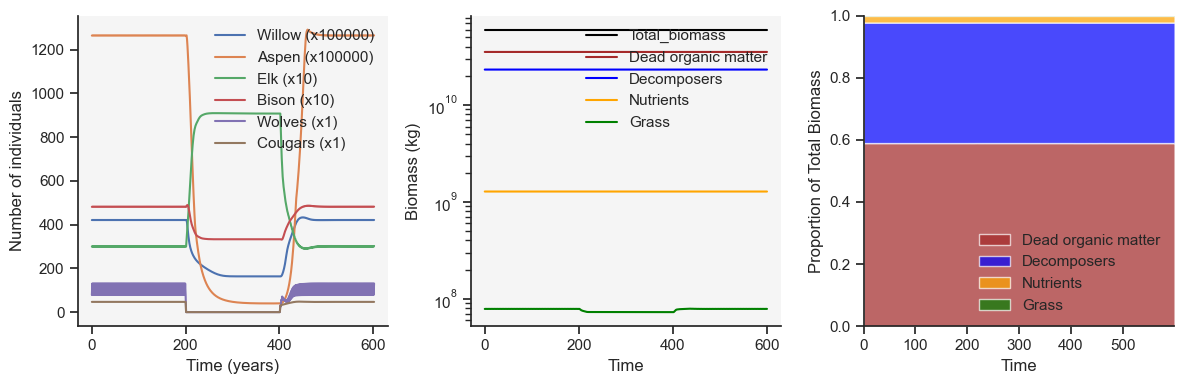

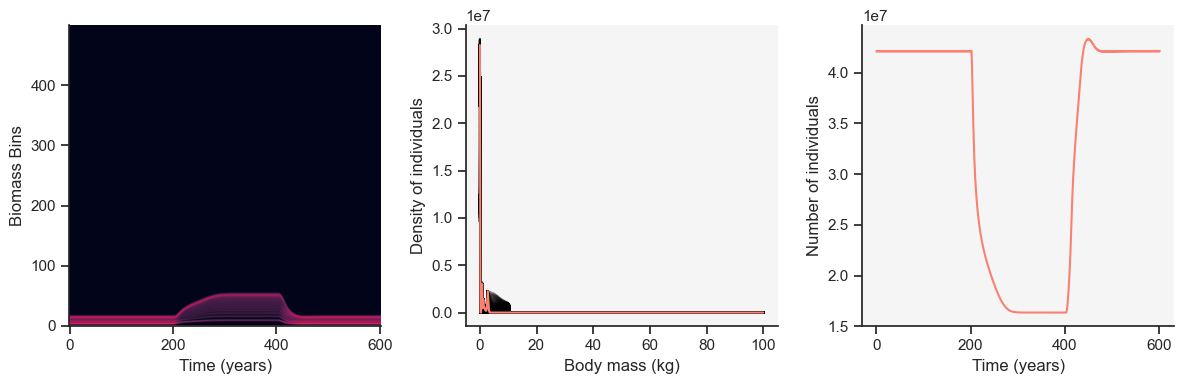

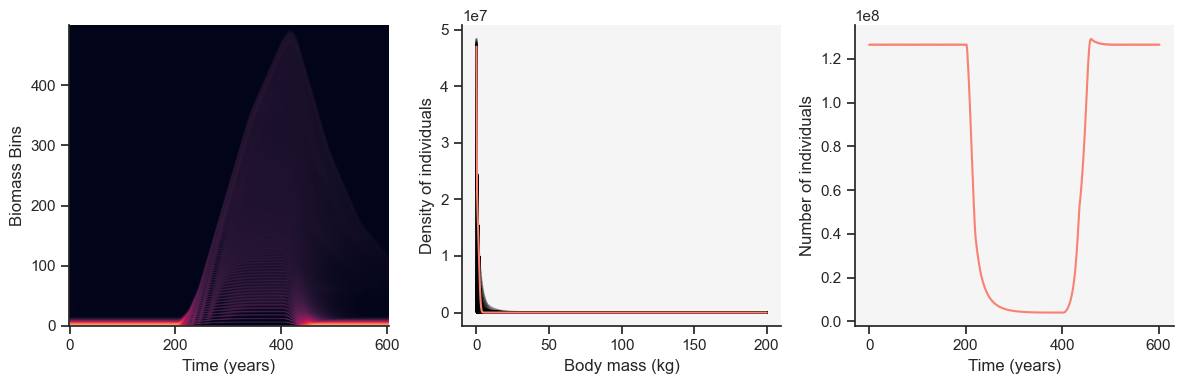

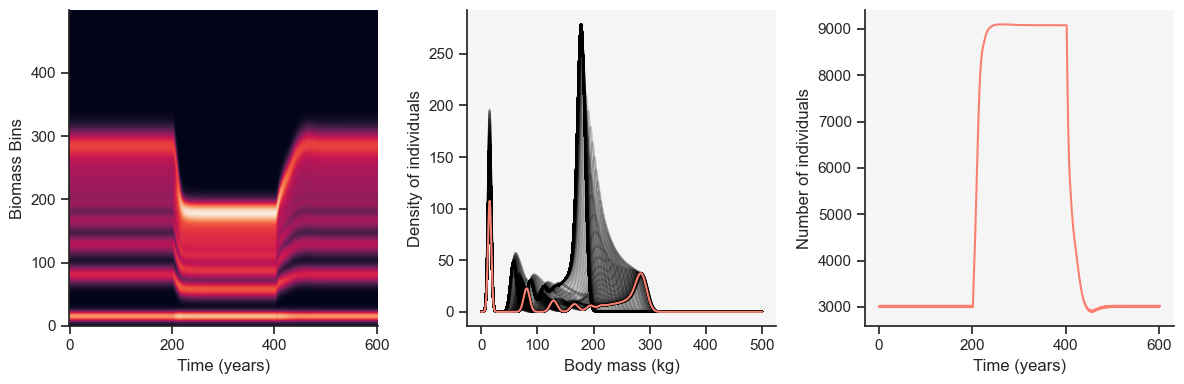

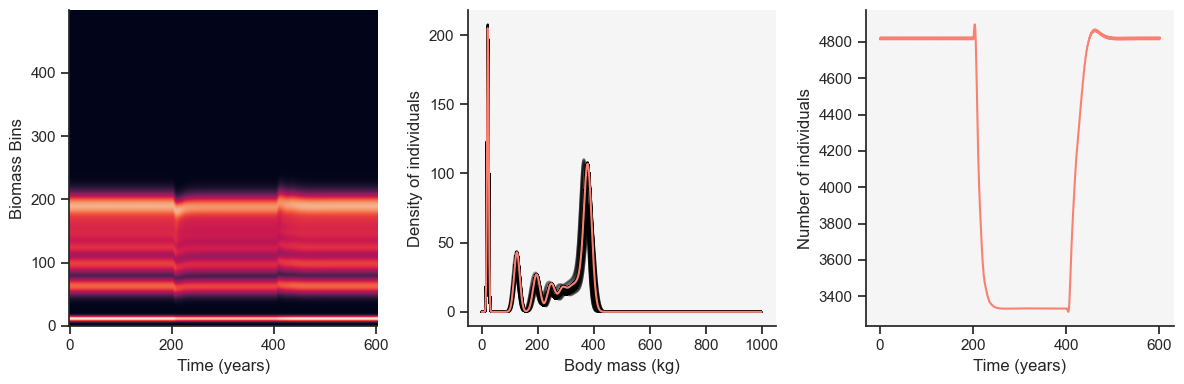

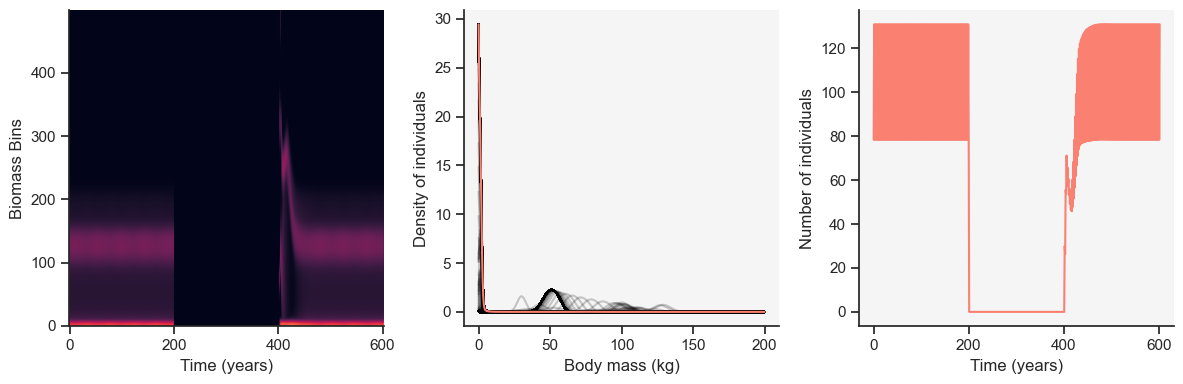

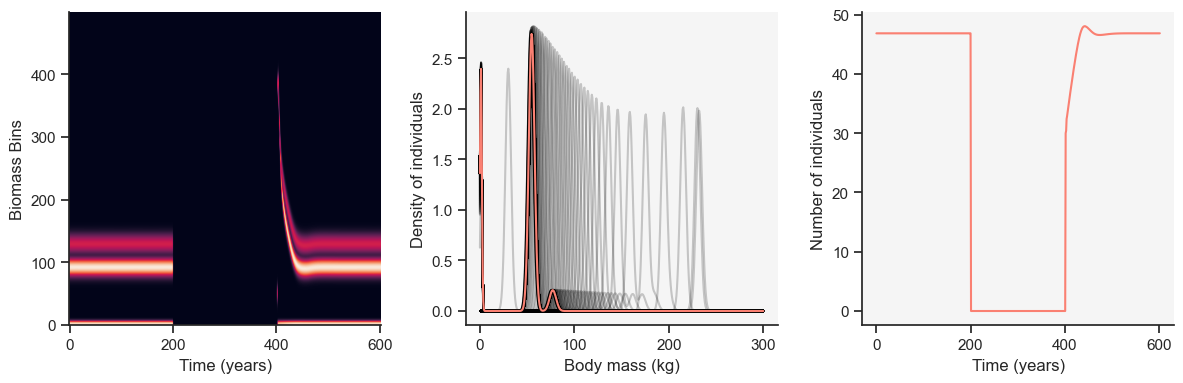

In [15]:
####################
## VISUALISATIONS ##
####################

## FIGURE 
plt.figure(figsize=(12, 4))

## Scales
scales = [100000, 100000, 10, 10, 1, 1]
labels = [f"Willow (x{scales[0]})",
          f"Aspen (x{scales[1]})",
          f"Elk (x{scales[2]})",
          f"Bison (x{scales[3]})",
          f"Wolves (x{scales[4]})",
          f"Cougars (x{scales[5]})",
         ]
#
plt.subplot(1,3,1)
for i in range(6):
    plt.plot(NNNNzt[i,:].sum(1) / scales[i], label=labels[i])
#
# plt.title('$N^{(i)}(t)$')
plt.xlabel('Time (years)')
plt.ylabel('Number of individuals')
#
plt.legend(loc='upper right', frameon=False)    
# plt.yscale('log')
# plt.show()

## Define color vector
color_vector = {
  'Total_biomass': 'black',
  'Dead organic matter': 'brown',
  'Decomposers': 'blue',
  'Nutrients': 'orange',
  'Grass': 'green'
}

## Ecosystem dynamics
plt.subplot(1,3,2)
plt.plot(tt, ttotal_biomass, label='Total_biomass', color=color_vector['Total_biomass'])
plt.plot(tt, DDt, label='Dead organic matter', color=color_vector['Dead organic matter'])
plt.plot(tt, BBt, label='Decomposers', color=color_vector['Decomposers'])
plt.plot(tt, PPt, label='Nutrients', color=color_vector['Nutrients'])
plt.plot(tt, GGt, label='Grass', color=color_vector['Grass'])
plt.legend(loc='upper right', frameon=False)
plt.xlabel('Time')
plt.ylabel('Biomass (kg)')
plt.yscale("log")
# plt.grid(c='white')

## Calculate proportions
total_biomass = DDt.clone().detach() + BBt.clone().detach() + PPt.clone().detach() + GGt.clone().detach()
D_prop = DDt.clone().detach() / total_biomass
B_prop = BBt.clone().detach() / total_biomass
P_prop = PPt.clone().detach() / total_biomass
G_prop = GGt.clone().detach() / total_biomass

## Convert tensors to numpy for plotting
proportions = torch.stack([D_prop, B_prop, P_prop, G_prop], dim=0).numpy()

## Stacked area plot
plt.subplot(1,3,3)
labels = ['Dead organic matter', 'Decomposers', 'Nutrients', 'Grass']
colors = [color_vector[label] for label in labels]  # Extract colors for each label
plt.stackplot(tt, proportions, labels=labels, colors=colors, alpha=0.7)

## Remove gap between plot and y-axis
plt.xlim(0, np.max(tt)-1)
plt.ylim(0,1)

## Customize plot
plt.legend(loc='lower right', frameon=False)
plt.xlabel('Time')
plt.ylabel('Proportion of Total Biomass')
# plt.title('Change in Biomass Proportions Over Time')
# plt.grid(c='white')

## End figure
plt.tight_layout()
plt.show()


## FIGURE 2
exponents = [.25, 0.25, .25, .25, .25, .25]
for i in range(6):

    ## Visualise matrices
    plt.figure(figsize=(12, 4))
    #
    plt.subplot(1, 3, 1)
    plt.imshow(NNNNzt[i].T**exponents[i], origin='lower', aspect='auto')
    # plt.colorbar()
    # plt.title('$N^{(i)}(z,t)$')
    plt.xlabel('Time (years)')
    plt.ylabel('Biomass Bins')
    #
    plt.subplot(1, 3, 2)
    for t, NNzt in enumerate(NNNNzt[i]):
        plt.plot(zzz[i], NNzt, alpha=0.2, color='black')
    plt.plot(zzz[i], NNzt, color='salmon')
    # plt.colorbar()
    # plt.title('$N^{(i)}(z,t)$')
    plt.xlabel('Body mass (kg)')
    plt.ylabel('Density of individuals')
    #
    plt.subplot(1, 3, 3)
    plt.plot(NNNNzt[i,:].sum(1), color='salmon')
    # plt.colorbar()
    # plt.title('$N^{(i)}(t)$')
    plt.xlabel('Time (years)')
    plt.ylabel('Number of individuals')
    #
    plt.tight_layout()
    plt.show()

#
###

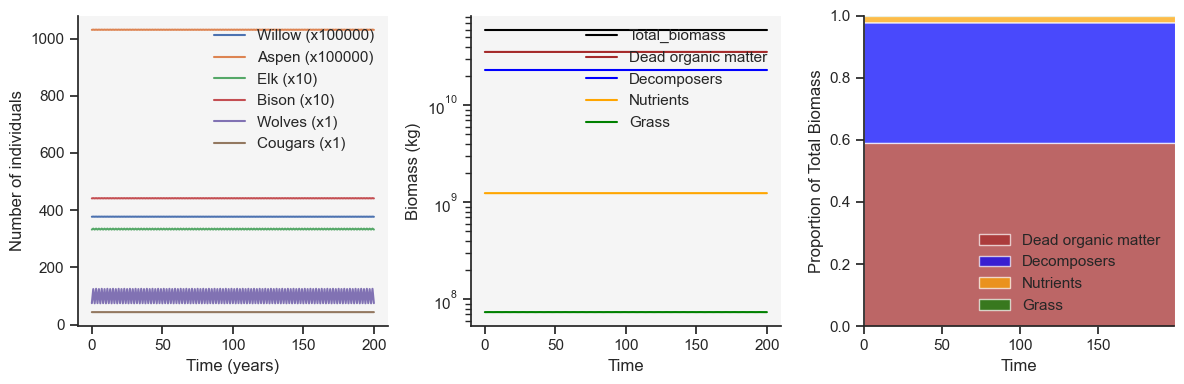

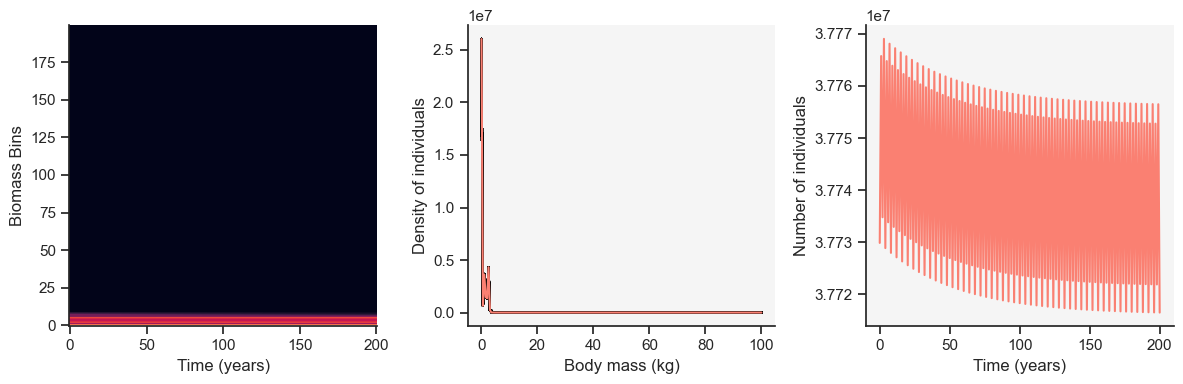

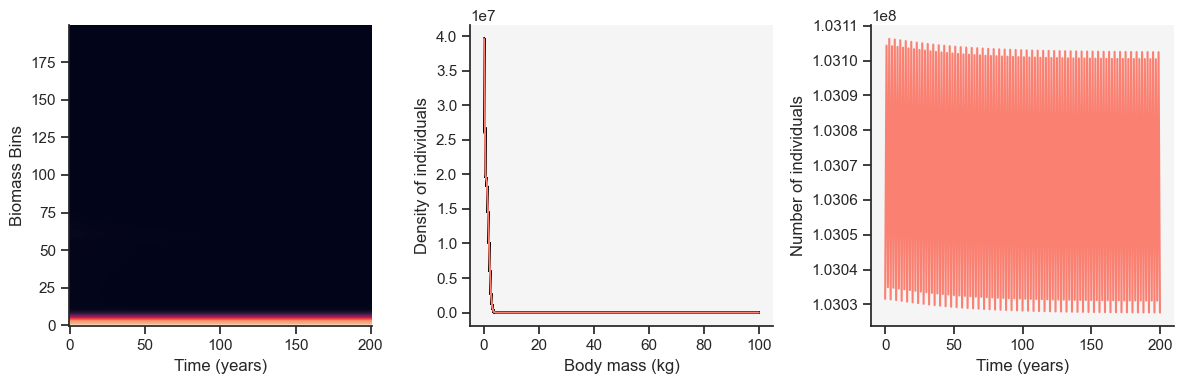

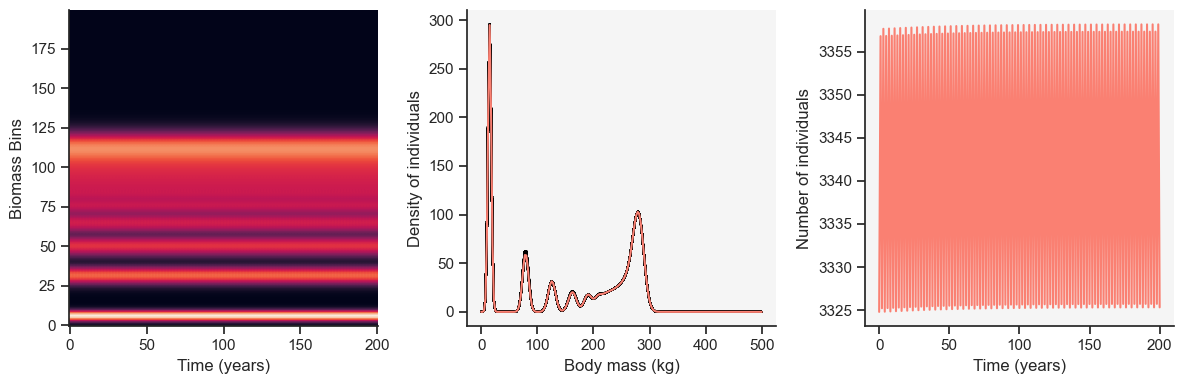

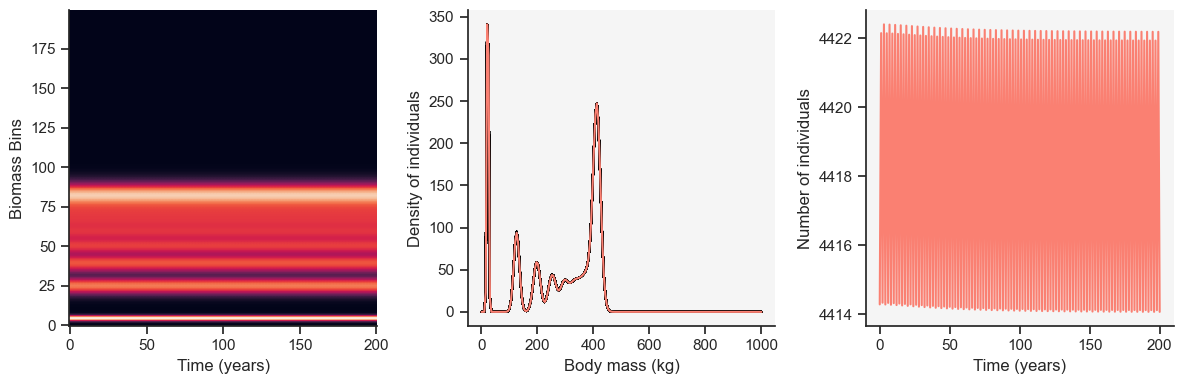

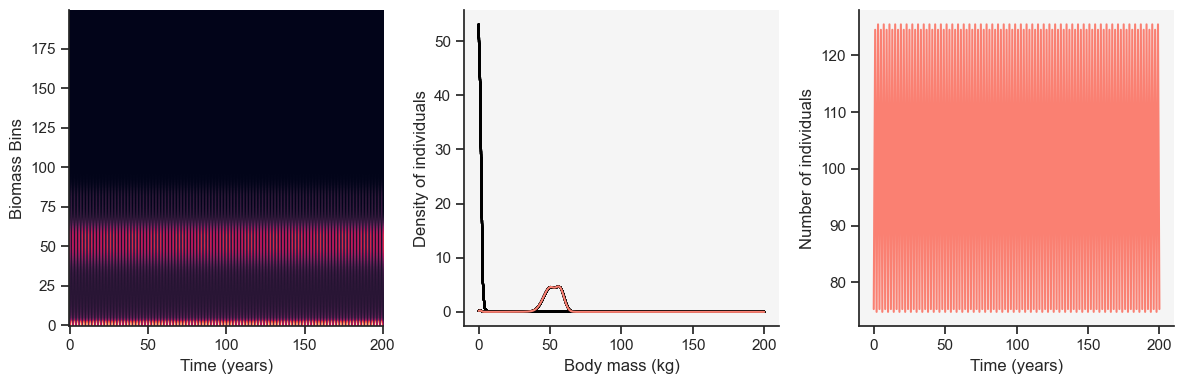

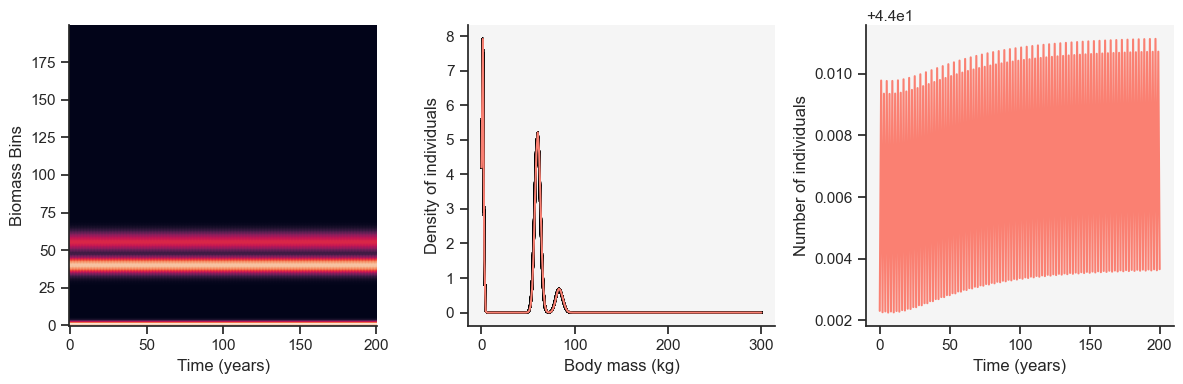

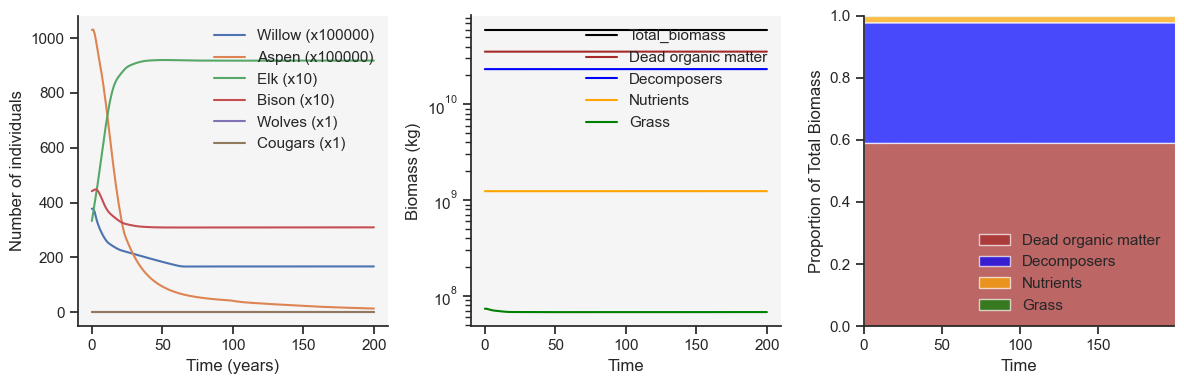

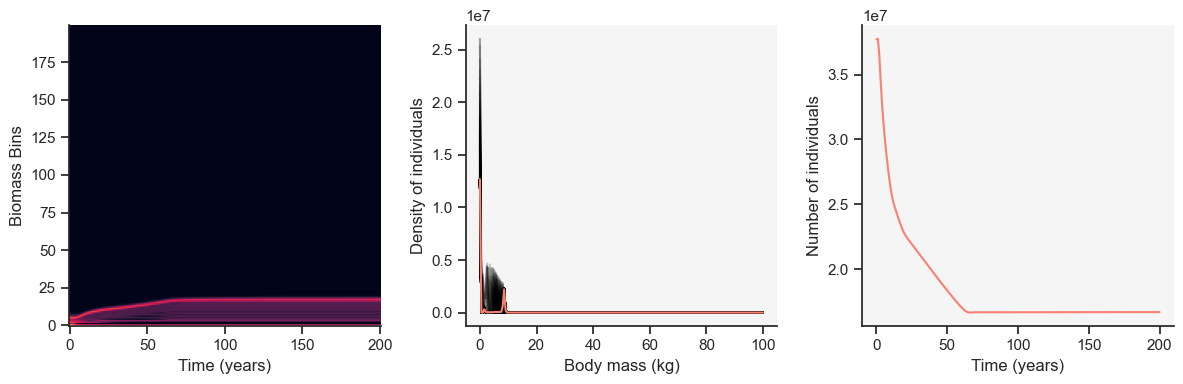

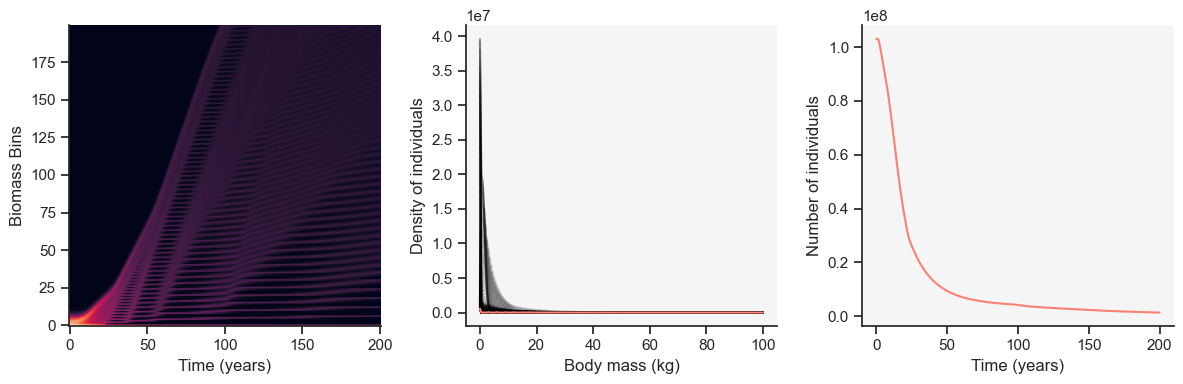

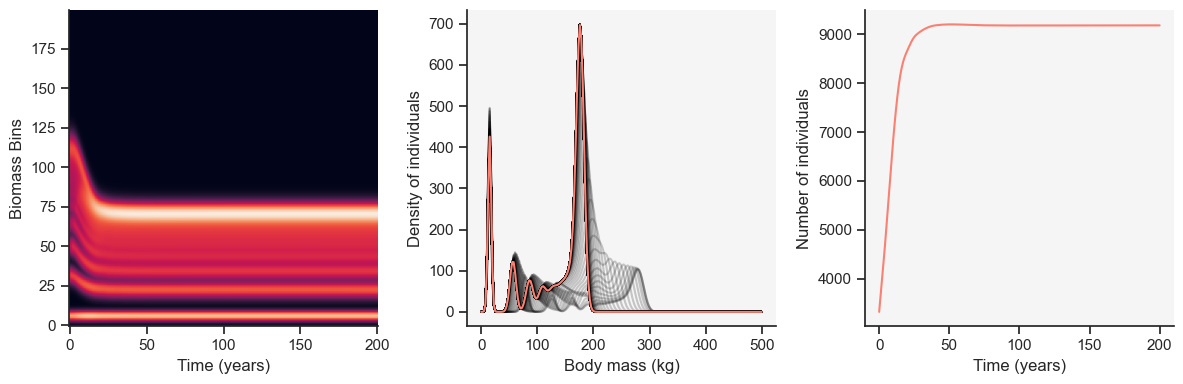

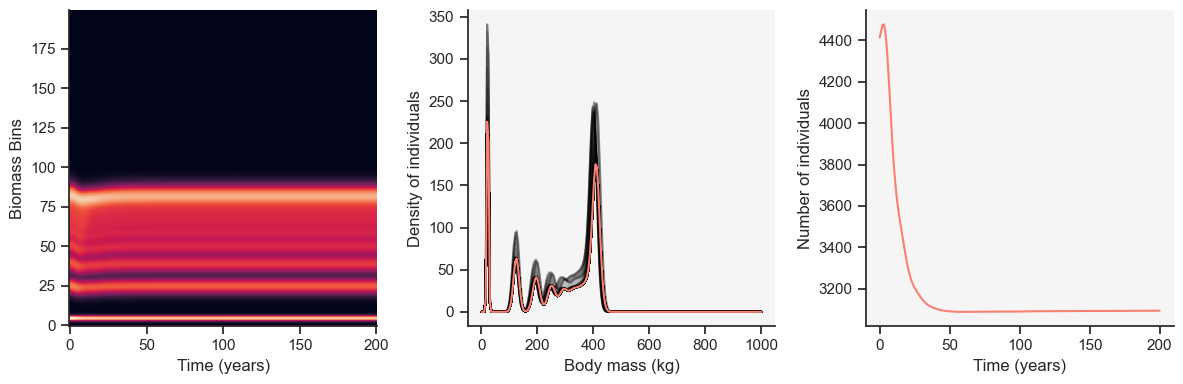

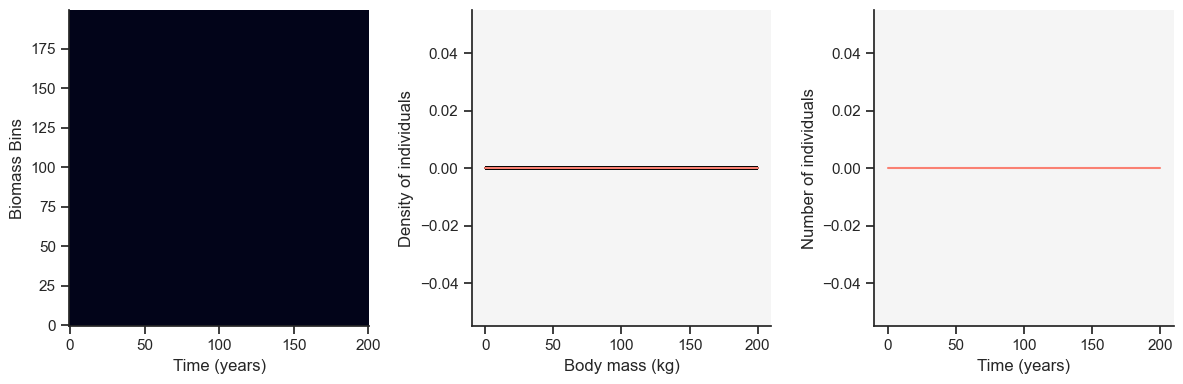

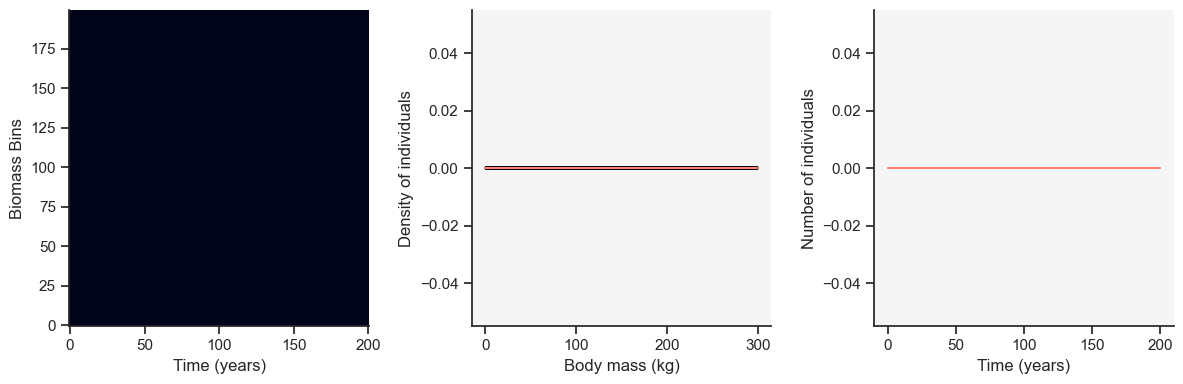

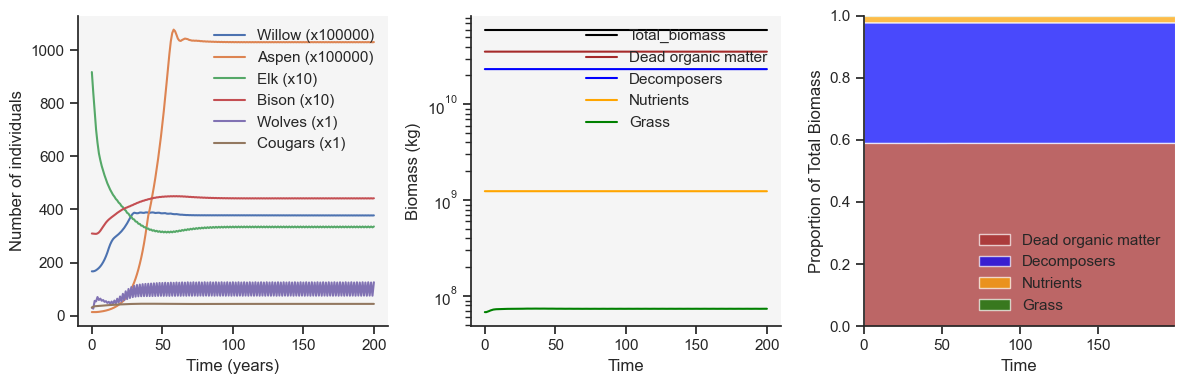

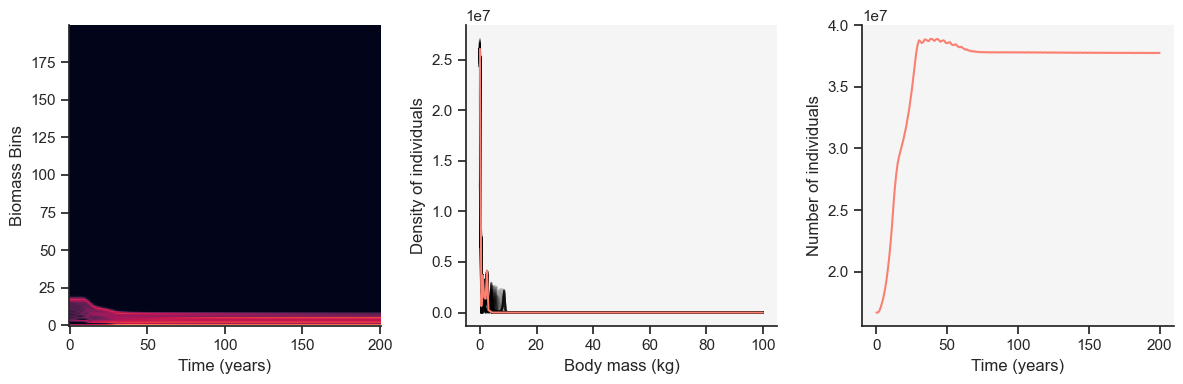

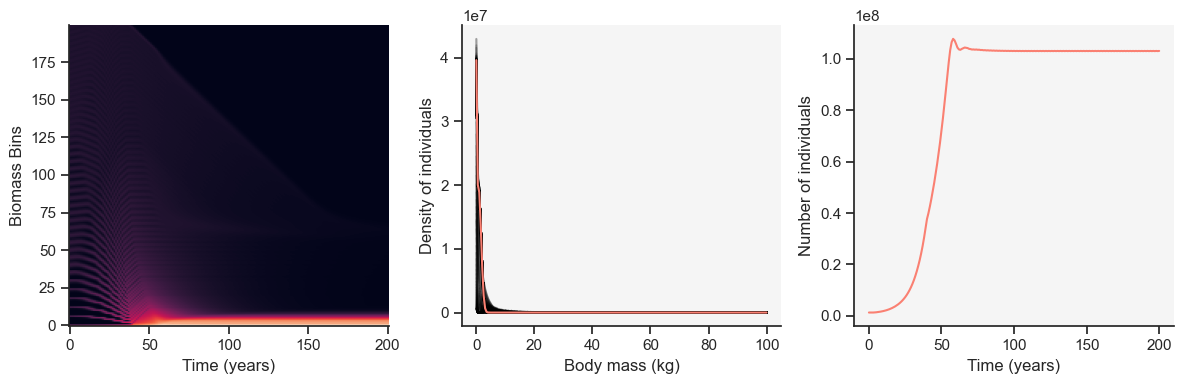

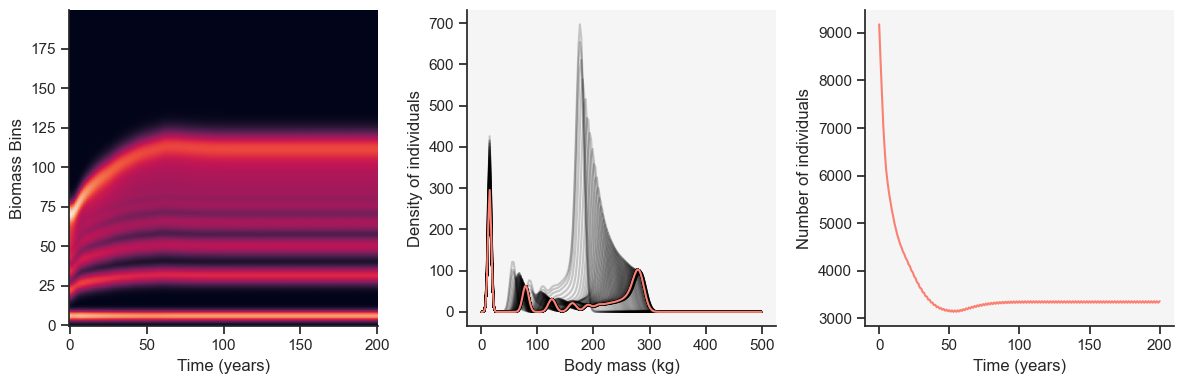

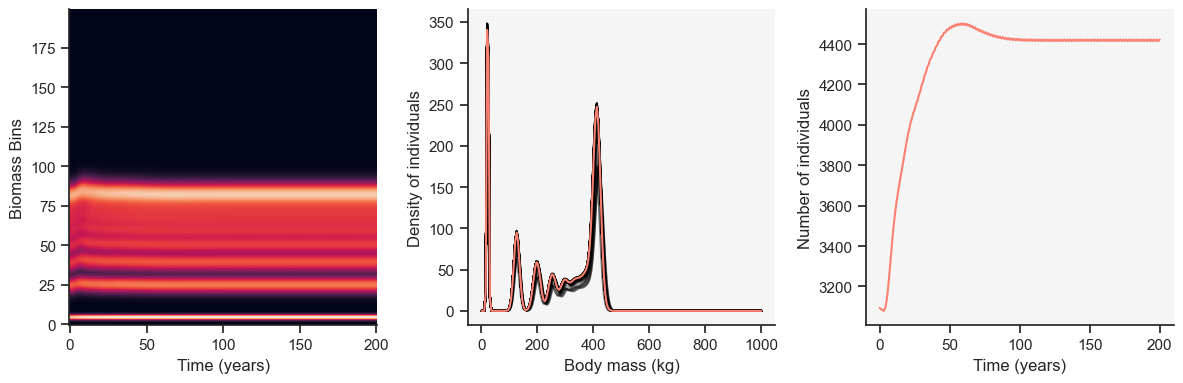

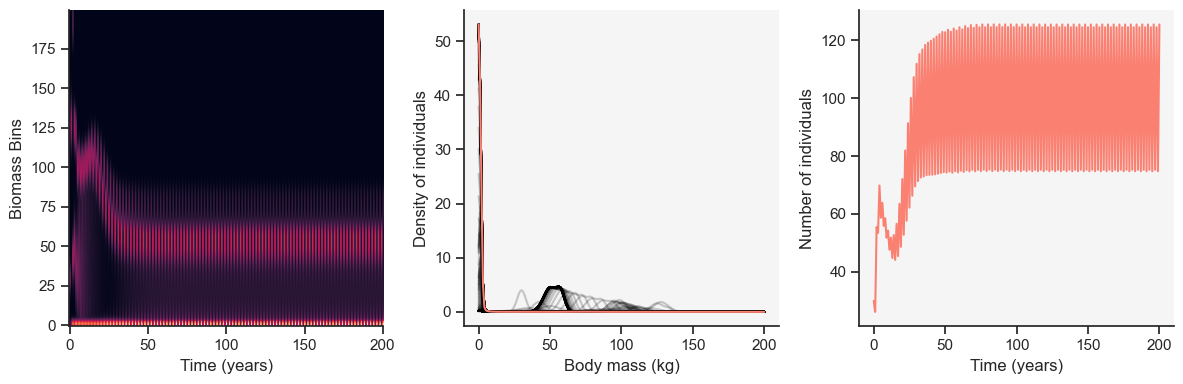

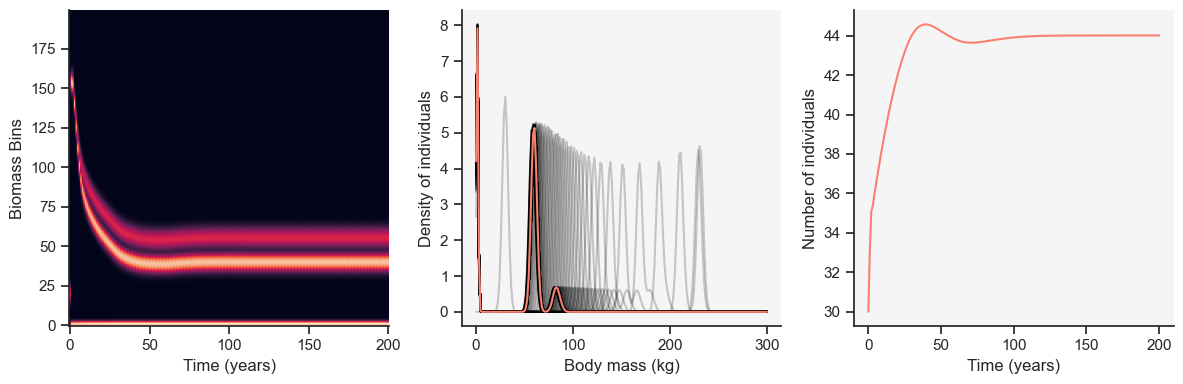

In [19]:
plot_model(predictions_1)
plot_model(predictions_2)
plot_model(predictions_3)